<a href="https://colab.research.google.com/github/amavi-e/A-TinyML-Powered-Wearable-Navigation-Aid-for-the-Visually-Impaired/blob/model-training/irp_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IRP model training - COMPACT TinyML variant with its own teacher (distillation, multi-object, int8, under 1 MB including speech)
Same pipeline as the v6 multi-label notebook (same data, same targets, same asymmetric loss, per-position presence scores, calibration and alert logic), but with a **much smaller network** so that the model and the speech fit a real TinyML device.

**Use a GPU runtime (T4).** Needs `IRP/final_dataset_v4.tar` on Drive. Run the cells from top to bottom.

**What is different (all in cell 0, marked COMPACT):** MobileNetV2 width **0.35**, input **128 x 128** (the 320 x 320 dataset pictures are shrunk with anti-aliasing), the heads read the stage-5 features (`block_16_project_BN`) instead of the 1280-channel final layer, much narrower heads and dense layers, lower dropout, no pruning, and the speech is stored as **about 33 short 8 kHz mu-law pieces** that the device joins instead of 81 full sentences.

**What you get (printed at the end, cell 17):** the model size in KB, the speech size in KB, their total, and an **estimate of the RAM** the model's tensors need (the TFLite-Micro tensor arena). Expect roughly 0.55 MB for the model, 0.15 MB for the speech and 300 KB of arena at 128 px (about 170 KB at 96 px: set `IMG_SIZE = 96` in cell 0 for a smaller board).

**Knowledge distillation with its own teacher (cells 4a-4c):** the compact model learns from a large model's soft answers (`KD_W`, `KD_T` in cell 0). **No earlier file is needed:** if `IRP/teacher/float_model.keras` is not on Drive, the cells marked *TEACHER STAGE* first train a large model with the v6 settings (roughly 3-4 hours on a T4), save it to Drive, and then switch back to the compact settings. If the file already exists (for example after an interrupted run), the teacher stage is skipped. The large model is used **only during training**; the device runs just the compact model. Set `TRAIN_TEACHER = False` or `USE_TEACHER = False` in cell 0 to train without a teacher.

**Honest trade-off:** a network this small is less accurate than the 4.3 MB v6 model, especially for small and far objects. Report both models: the large one as the best accuracy, this one as the TinyML-class result, and the size / accuracy trade-off between them.

**Files written** (local `/content/model_out`, copied to `IRP/irp-model-compact` on Drive): the final `.tflite`, float model and weights, training curves, `alert_config.json` for the firmware, and the speech pieces.

## Part A - Setup, class table and rules

In [1]:
# CELL 0 - SETUP: Keras switch, installs, GPU check, Drive, paths and every setting you may want to change. Run this first in every session.
import os, sys, subprocess   # operating-system, interpreter and process tools
LOADED_EARLY = 'tensorflow' in sys.modules and os.environ.get('TF_USE_LEGACY_KERAS') != '1'   # True if TensorFlow was imported before the switch below could be set
os.environ['TF_USE_LEGACY_KERAS'] = '1'   # make tf.keras the classic Keras 2 (tf_keras): the pruning toolkit only works with it
if LOADED_EARLY:   # the switch came too late
    raise RuntimeError('TensorFlow was already imported. Use Runtime > Restart session, then run this cell first.')   # tell the user what to do
import importlib.metadata as md   # reads installed package versions without importing them
for pkg in ('tensorflow', 'tensorflow-cpu'):   # the TensorFlow package may be listed under either name
    try:   # ask for its version
        TF_VERSION = md.version(pkg); break   # found it
    except md.PackageNotFoundError:   # not installed under this name
        continue   # try the next name
TF_MM = '.'.join(TF_VERSION.split('.')[:2])   # major.minor, for example 2.20
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', f'tf_keras~={TF_MM}.0', 'tensorflow-model-optimization', 'gTTS'], check=True)   # install a tf_keras that matches TensorFlow (a mismatch would upgrade TensorFlow itself)
import json, csv, re, time, math, random, shutil, zlib, wave   # standard-library tools used below
from pathlib import Path   # object-style file paths
import numpy as np   # arrays
import tensorflow as tf   # the deep-learning library
import tensorflow_model_optimization as tfmot   # quantization-aware training and pruning toolkit
import matplotlib.pyplot as plt   # charts and image grids
from google.colab import drive   # Google Drive access
keras = tf.keras   # shortcut (this is classic Keras because of the switch above)

# ---- GPU check (training needs a GPU: Runtime > Change runtime type > T4 GPU) ----
ALLOW_CPU = False   # set True only for a tiny dry run; real training on CPU would take days
gpus = tf.config.list_physical_devices('GPU')   # GPUs that TensorFlow can see
print('TensorFlow', tf.__version__, '| GPUs found:', gpus)   # show what was found
if not gpus and not ALLOW_CPU:   # no GPU and no permission to continue without one
    raise RuntimeError('No GPU found. Runtime > Change runtime type > T4 GPU, then run again.')   # stop with a clear message
for g in gpus:   # every GPU
    tf.config.experimental.set_memory_growth(g, True)   # take GPU memory only when needed

# ---- Drive and folders ----
DRIVE = '/content/drive/MyDrive'   # where Google Drive appears inside Colab
if not os.path.exists(DRIVE):   # Drive is not mounted yet
    drive.mount('/content/drive')   # asks you to allow Drive access
TAR = f'{DRIVE}/IRP/final_dataset.tar'   # the verified dataset archive made by the preprocessing notebook
DATA = '/content/final_dataset'   # the archive is unpacked here (fast local disk)
OUT = '/content/model_out'   # everything made in this notebook is written here first
OUT_DRIVE = f'{DRIVE}/IRP/irp-model-compact'   # COMPACT: output folder on Drive
os.makedirs(OUT, exist_ok=True)   # create the local output folder

# ---- settings (all in one place) ----
SEED = 42   # random seed so runs are repeatable
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)   # seed Python, NumPy and TensorFlow
IMG_SIZE = 144   # COMPACT: model input size in pixels (the dataset images are 320 x 320 and are shrunk with anti-aliasing). Estimated RAM for the tensors: 128 px about 295 KB, 144 px about 373 KB, 160 px about 461 KB
BATCH = 32   # images per training step
ALPHA = 0.5   # COMPACT: MobileNetV2 width 0.5 (0.35 gives about 0.55 MB, 0.5 about 0.85 MB; both have ImageNet weights)
WEIGHTS = 'imagenet'   # start from ImageNet-trained backbone weights (None = random start, only for quick tests)
EPOCHS_HEAD = 12   # maximum epochs with the backbone frozen (v3 peaked at about epoch 7-8)
EPOCHS_FINE = 60   # COMPACT: maximum epochs with the whole network unfrozen (a small network keeps improving longer; early stopping ends it sooner)
LR_HEAD = 3e-4   # learning rate while only the new layers train
LR_FINE = 1e-4   # COMPACT: fine-tuning learning rate (3e-5 was too small for this network: training F1 stayed below validation F1, so it was under-fitting)
FINE_LR_PATIENCE = 4   # COMPACT: wait longer before halving the learning rate (2 made it collapse to 2e-6 within 25 epochs)
FINE_STOP_PATIENCE = 8   # COMPACT: wait longer before early stopping (the F1 kept creeping up when it was stopped)
EMA_DECAY = 0.999   # average the weights over the last ~1000 steps of fine-tuning (0 = off)
CLIPNORM = 1.0   # gradient clipping (prevents sudden collapses, especially while pruning)
LABEL_SMOOTH = 0.02   # softens the present / absent targets a little (kept small: with 27 independent yes/no outputs a large value would stop the scores ever getting near 0)
SIZE_LOSS_W = 10.0   # weight of the size (distance) loss relative to the presence loss
HFOV_DEG = 70.0   # horizontal field of view of the wearable camera in degrees (look up or measure it for the real camera)
BAND_LIMITS_M = (1.0, 2.0, 4.0)   # band edges in metres: <1 very close, 1-2 close, 2-4 near, >4 far
DETECT_THR = 0.50   # a class counts as present when its probability is at least this (cell 13b fits the real value on the validation split)
UNSURE_MIN = 0.25   # when nothing reaches DETECT_THR, the strongest candidate with at least this probability is announced as a generic 'object'
TOP_K = 3   # at most this many objects are considered per frame (the most urgent first)
FILL_SIZE = 0.85   # an object whose size (square root of its box area) is at least this fraction of the picture counts as very close, whatever it is
TARGET_MB = 0.9   # COMPACT: wanted size of the int8 .tflite file in MB (model plus speech must stay under 1 MB; width 0.5 gives about 0.85 MB)
MAX_ACC_DROP = 0.01   # largest drop of the detection score (mean average precision) allowed after compression (0.01 = 1 percentage point)
MAX_SIZE_RISE = 0.02   # largest increase of the size (distance) error allowed after compression
L2_WEIGHT = 1e-4   # weight decay (L2) on the new layers: keeps weights small and reduces over-fitting
DROP1, DROP2 = 0.15, 0.1   # COMPACT: dropout after fc1 / fc2 (very low: the small network is under-fitting, so it needs less regularisation)
LARGE_LAYER = 'block_16_project_BN'   # COMPACT: the coarse feature map the heads read; this skips the final 1280-channel convolution, which alone would cost about 150 KB
HEAD_CH = 64   # COMPACT: channels of each of the three heads
FC2_UNITS = 64   # COMPACT: units of the second fully connected layer
SIZE_FC_UNITS = 32   # COMPACT: units of the small size branch
FC1_UNITS = 128   # COMPACT: units of the first fully connected layer
NOISY_LABELS = [('coco', 'vegetation')]   # (source, class) pairs whose labels are unreliable: COCO has no tree / bush box, so 'no vegetation' is often wrong there. Such entries are left out of the metrics; absent ones count only weakly in the loss
WEAK_NEG_W = 0.3   # loss weight of 'probably absent' entries: a specialist class (one that some source labels on its own, e.g. stairs) in a picture from a source that does not label it
SIZE_MAP_CH = 8   # COMPACT: channels of the small spatial map that feeds the size head
MIN_TRAIN_SIZE = 0.0   # TRAINING images whose main object is smaller than this are dropped (0 = keep all; the val and test splits are never filtered)
MULTI_MIN_AREA = 0.003   # floor: a box smaller than this share of the picture is never counted as present
IGNORE_BEYOND_M = 6.0   # an object that is farther than this (by its own class's typical size, cell 2 formula) would be silent anyway, so it is IGNORED by the presence loss and the metrics: neither a positive nor a negative
TEACHER_PATH = f'{DRIVE}/IRP/teacher/float_model.keras'   # the large teacher model on Drive (trained by this notebook when missing, or copied here from an earlier v6 run)
USE_TEACHER = 'auto'   # True / False / 'auto' (use it only when the file above exists)
KD_W = 0.85   # weight of the teacher in the presence loss (0.7 before; the model now overfits its hard labels a little, so it leans more on the teacher)
KD_T = 2.0   # softening temperature of the teacher's probabilities (higher = softer, carries more about similar classes)
ASL_GAMMA_NEG = 2.0   # asymmetric loss: how strongly easy ABSENT classes are down-weighted (0 = plain cross-entropy, 2-4 = typical for multi-label)
ASL_GAMMA_POS = 0.0   # the same for present classes (0 = full weight for every present object)
ASL_CLIP = 0.05   # absent classes with a probability below this cost nothing (probability shifting)
ASL_SCALE = 3.0   # keeps the presence loss about as large as before the asymmetric loss, relative to the size loss
POS_WEIGHT = 1.0   # a present object counts this many times as much as an absent one in the presence loss (most of the 27 classes are absent in any picture)
SRC_MIN_IMAGES = 20   # a source dataset 'knows' a class when at least this many of its pictures contain it; classes a source never labels are unknown (ignored), not absent
DANGER_RECALL_TARGET = 0.85   # cell 13b lowers the global detection threshold until at least this share of the real danger objects (hazard level 2) is found on the validation split
THR_SHRINK = 0.25   # each class's fitted threshold is pulled this far towards the global one (0 = trust the per-class fit fully; its validation sample is only about 100 pictures per class)
DANGER_BETA = 2.0   # per-class thresholds: danger classes are tuned with F-beta, beta = this (recall counts 2x as much as precision); the other classes use plain F1
DANGER_LOSS_W = 1.0   # COMPACT: off. 1.5 was tried and made every score slightly worse (mAP 0.766 -> 0.757), so it stays at 1.0
MISSED_NEAR_TARGET = 0.05   # calibration aims at reporting at most this share of truly near (< 2 m) objects as farther away
RUN_PRUNING = False   # COMPACT: pruning is not needed, the model is already small
EPOCHS_PRUNE = 6   # epochs of pruning fine-tuning (if it runs)
PRUNE_FINAL_SPARSITY = 0.50   # share of the pruned layers' weights that end up zero
CALIB_PER_CLASS = 11   # calibration images per class for the int8 conversion (27 x 11 = 297)
AUDIO_RATE = 6000   # sample rate of the speech in Hz (8000 before); about 25% smaller speech files (142 KB -> 108 KB in my test), still understandable
AUDIO_MODE = 'fragments'   # COMPACT: store about 33 short pieces that the device joins, not 81 full sentences
AUDIO_CODEC = 'adpcm_ima_wav'   # COMPACT: 4-bit IMA ADPCM WAV (a quarter of the size of 16-bit; a microcontroller decodes it with a few dozen lines). Use pcm_mulaw for 8-bit mu-law (simpler to decode, twice the size)
SPEECH_LANG = 'en'   # language of the speech clips

# ---- teacher stage settings (distillation without any earlier file) ----
TRAIN_TEACHER = True   # True = if no teacher file exists, train one first in this notebook (roughly 3-4 hours on a T4) and save it to Drive; False = never train one
TEACHER_EPOCHS_HEAD = 8   # teacher: maximum epochs with the backbone frozen (early stopping usually ends it sooner)
TEACHER_EPOCHS_FINE = 30   # teacher: maximum epochs with the whole network unfrozen (early stopping usually ends it sooner)
TEACHER_CFG = dict(ALPHA=1.0, IMG_SIZE=None, HEAD_CH=256, FC1_UNITS=384, FC2_UNITS=256, SIZE_FC_UNITS=128, SIZE_MAP_CH=16, LARGE_LAYER='out_relu', DROP1=0.5, DROP2=0.4, EPOCHS_HEAD=TEACHER_EPOCHS_HEAD, EPOCHS_FINE=TEACHER_EPOCHS_FINE, KD_W=0.0, LR_FINE=3e-5, FINE_LR_PATIENCE=2, FINE_STOP_PATIENCE=5)   # the settings of the LARGE model (the v6 settings) that replace the compact ones during the teacher stage (IMG_SIZE None = the stored picture size SRC_SIZE, filled in when the stage starts)


TensorFlow 2.21.0 | GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive


In [2]:
# CELL 1 - CLASS TABLE: the 27 classes with the name that is spoken, a typical real-world size (used for distance) and a hazard level (used for priority).
CLASS_LIST = [   # same order as classes.txt in the dataset (id = position in this list)
    'person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign',   # road users and street furniture
    'fire hydrant', 'bench', 'stairs', 'chair', 'couch', 'table', 'door', 'bed', 'toilet',   # obstacles and indoor items
    'sink', 'tv', 'dog', 'cat', 'bird', 'animal', 'object', 'crosswalk', 'vegetation', 'pothole']   # animals, groups and ground hazards
CLASS_INFO = {   # class -> (spoken name, typical real size in metres, hazard 0/1/2); EDIT these numbers after you measure real photos
    'person': ('person', 0.9, 1), 'bicycle': ('bicycle', 1.0, 2), 'car': ('car', 1.7, 2),   # people and vehicles
    'motorcycle': ('motorcycle', 1.1, 2), 'bus': ('bus', 2.8, 2), 'truck': ('truck', 2.6, 2),   # more vehicles (hazard 2 = danger)
    'traffic light': ('traffic light', 0.6, 0), 'stop sign': ('stop sign', 0.75, 0),   # landmarks (hazard 0 = information)
    'fire hydrant': ('fire hydrant', 0.5, 1), 'bench': ('bench', 1.1, 1), 'stairs': ('stairs', 1.5, 2),   # street obstacles (1 = obstacle), stairs are a fall danger
    'chair': ('chair', 0.7, 1), 'couch': ('couch', 1.3, 1), 'table': ('table', 1.0, 1),   # indoor obstacles
    'door': ('door', 1.3, 1), 'bed': ('bed', 1.7, 1), 'toilet': ('toilet', 0.55, 0),   # door and bed obstruct, toilet is a landmark
    'sink': ('sink', 0.5, 0), 'tv': ('tv', 0.75, 0), 'dog': ('dog', 0.6, 2),   # indoor landmarks and a dog (can move suddenly)
    'cat': ('cat', 0.35, 1), 'bird': ('bird', 0.2, 0), 'animal': ('animal', 1.5, 2),   # smaller animals and large animals
    'object': ('object', 0.5, 1), 'crosswalk': ('crosswalk', 3.0, 0),   # catch-all obstacle and a landmark
    'vegetation': ('vegetation', 1.5, 1), 'pothole': ('pothole', 0.5, 2)}   # plants (obstacle) and a ground hazard
assert set(CLASS_INFO) == set(CLASS_LIST), 'CLASS_INFO must have exactly the classes of CLASS_LIST'   # catch typos early
NC = len(CLASS_LIST)   # number of classes
CLASS_ID = {n: i for i, n in enumerate(CLASS_LIST)}   # class name -> id
OBJECT_ID = CLASS_ID['object']   # id of the generic object class (used when the model is unsure)

def folder_name(cls):   # class name -> folder name used in the dataset
    return cls.replace(' ', '_')   # spaces become underscores


### Distance and priority rules
How a model output becomes spoken warnings:

1. **Which objects:** a class is present when its probability `sigmoid(score / temperature)` reaches the threshold fitted in cell 13b. If nothing reaches it but the strongest candidate is at least `UNSURE_MIN`, it is announced as a generic *object*.
2. **Distance:** `metres = typical_size / (size x 2 x tan(HFOV/2))`, per object, with that class's own size. An object that fills most of the picture (`FILL_SIZE`) is reported as very close.
3. **Band:** very close (< 1 m), close (1-2 m), near (2-4 m), far (> 4 m, silent).
4. **Priority** = table lookup on (band, hazard). The alerts of a frame are sorted by priority, then distance, and the manager plays the most urgent one that is allowed (cooldowns, no interruption by less urgent clips).

In [3]:
# CELL 2 - DISTANCE AND PRIORITY RULES: turns "class + apparent size" into metres, a distance band, a priority level and the sentence to speak.
BAND_NAMES = ['very close', 'close', 'near', 'far']   # distance bands, index 0 = most dangerous
PRIORITY_NAMES = ['none', 'info', 'warning', 'critical']   # priority levels, index = level (3 is the most urgent)
PRIORITY_TABLE = [   # rows = distance band, columns = hazard 0 / 1 / 2 -> priority level
    [2, 3, 3],   # very close: landmarks give a warning, obstacles and dangers are critical
    [1, 2, 3],   # close: dangers are critical, obstacles warn, landmarks inform
    [1, 1, 2],   # near: only dangers warn, everything else just informs
    [0, 0, 0]]   # far: stay silent
DIST_WORDS = ['less than one metre', 'one to two metres', 'two to four metres']   # what is said for each speaking band
LEAD = {3: 'Danger!', 2: 'Warning.', 1: ''}   # opening word per priority level
COOLDOWN_S = {3: 1.5, 2: 3.0, 1: 6.0}   # seconds before the same class may be announced again, per priority level
TAN_HALF = math.tan(math.radians(HFOV_DEG / 2))   # tangent of half the camera's horizontal field of view

def metres_from_size(cls_id, size):   # apparent size (square root of the box area, 0-1) -> distance in metres
    ref = CLASS_INFO[CLASS_LIST[cls_id]][1]   # typical real size of this class
    m = float(np.clip(ref / (max(float(size), 0.02) * 2 * TAN_HALF), 0.3, 30.0))   # pinhole-camera formula, limited to 0.3-30 m
    if float(size) >= FILL_SIZE:   # the object fills most of the picture (big objects cannot look larger than the picture, so the formula would stop at about 1-2 m)
        m = min(m, BAND_LIMITS_M[0] - 0.01)   # safety first: report it as very close
    return m   # distance in metres

def band_of(metres):   # metres -> band index 0..3
    return int(sum(metres >= edge for edge in BAND_LIMITS_M))   # count how many band edges are passed

def priority_of(cls_id, band):   # (class, band) -> priority level 0..3
    return PRIORITY_TABLE[band][CLASS_INFO[CLASS_LIST[cls_id]][2]]   # row = band, column = the class's hazard level

def clip_name(cls_id, band):   # file name of the spoken clip for a class in a band
    return f"{folder_name(CLASS_LIST[cls_id])}_{BAND_NAMES[band].replace(' ', '_')}.wav"   # for example car_very_close.wav

def sentence(cls_id, band):   # the words spoken for a class in a band
    pr = priority_of(cls_id, band)   # how urgent this is
    lead = 'Stop!' if (band == 0 and pr == 3) else LEAD.get(pr, '')   # 'Stop!' for critical and very close, otherwise the usual opening word
    parts = [lead, CLASS_INFO[CLASS_LIST[cls_id]][0] + ',', DIST_WORDS[band] + '.']   # opening word, spoken name, distance phrase
    return ' '.join(p for p in parts if p)   # join the non-empty parts

# >>> CALIBRATION (also pasted into the stand-alone patch)
CAL = dict(temp=1.0, thr=DETECT_THR, thr_c=None, a=1.0, b=0.0, margin=0.0)   # set by cell 13b: temperature of the presence scores, global detection threshold, one threshold per class (None until fitted), size slope, size offset, safety margin (these start values change nothing)

def calibrated_size(size):   # raw size output -> corrected size (removes the bias, then leans towards 'closer')
    return float(np.clip((CAL['a'] * float(size) + CAL['b']) * (1.0 + CAL['margin']), 0.02, 1.0))   # linear fix, then a safety margin, kept inside 0.02-1
# <<< CALIBRATION

def thr_vec():   # the detection threshold of every class (27 numbers); the per-class ones once cell 13b has fitted them, otherwise the global one
    return np.asarray(CAL['thr_c'], dtype=np.float64) if CAL.get('thr_c') is not None else np.full(NC, float(CAL['thr']))   # array of thresholds

def sigmoid(z):   # scores -> probabilities of 'this class is present' (every class is judged on its own)
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64)))   # logistic function

def make_alert(cid, size, conf, unsure):   # one object (class id, raw size) -> the alert the device would give for it
    m = metres_from_size(cid, calibrated_size(size))   # distance estimate from the corrected size
    b = band_of(m)   # distance band
    pr = priority_of(cid, b)   # priority level
    return dict(cls=cid, name=CLASS_INFO[CLASS_LIST[cid]][0], conf=float(conf), unsure=unsure, metres=m, band=b, priority=pr,   # the decision ...
                clip=clip_name(cid, b) if pr > 0 else None, text=sentence(cid, b) if pr > 0 else '')   # ... and what to play / say (nothing when far)

def decide_all(logits, sizes):   # one camera frame (27 presence scores + 27 sizes) -> alerts for the objects in it, most urgent first
    p = sigmoid(np.asarray(logits, dtype=np.float64) / CAL['temp'])   # probability that each class is present
    sz = np.asarray(sizes, dtype=np.float64).reshape(-1)   # one size per class
    thr = thr_vec()   # threshold of each class
    dets = [make_alert(c, sz[c], p[c], False) for c in range(NC) if p[c] >= thr[c]]   # every class that is confidently present
    if not dets and p.max() >= UNSURE_MIN:   # nothing is certain but something may be there
        c = int(p.argmax())   # the strongest candidate
        dets = [make_alert(OBJECT_ID, sz[c], p[c], True)]   # announced as a generic object, with that candidate's size
    dets.sort(key=lambda d: (-d['priority'], d['band'], -d['conf']))   # most urgent first, then closest, then most certain
    return dets[:TOP_K]   # only the first few matter

# ---- print the rule table so you can check every class ----
print(f"{'class':14s}{'hazard':>7s}{'ref m':>7s}   priority at: very close / close / near     example sentence (close)")   # header
for cid, cname in enumerate(CLASS_LIST):   # one row per class
    spoken, ref, hz = CLASS_INFO[cname]   # its table entry
    prs = [PRIORITY_NAMES[priority_of(cid, b)] for b in range(3)]   # priority in the three speaking bands
    print(f'{cname:14s}{hz:7d}{ref:7.2f}   {prs[0]:>9s} / {prs[1]:>8s} / {prs[2]:>8s}     {sentence(cid, 1)}')   # one line per class


class          hazard  ref m   priority at: very close / close / near     example sentence (close)
person              1   0.90    critical /  warning /     info     Warning. person, one to two metres.
bicycle             2   1.00    critical / critical /  warning     Danger! bicycle, one to two metres.
car                 2   1.70    critical / critical /  warning     Danger! car, one to two metres.
motorcycle          2   1.10    critical / critical /  warning     Danger! motorcycle, one to two metres.
bus                 2   2.80    critical / critical /  warning     Danger! bus, one to two metres.
truck               2   2.60    critical / critical /  warning     Danger! truck, one to two metres.
traffic light       0   0.60     warning /     info /     info     traffic light, one to two metres.
stop sign           0   0.75     warning /     info /     info     stop sign, one to two metres.
fire hydrant        1   0.50    critical /  warning /     info     Warning. fire hydrant, on

## Part B - Data
Unpack the verified dataset on the fast local disk, index it (main class = folder; multi-label targets from the label files).

In [4]:
# CELL 3 - GET THE DATASET: unpack final_dataset.tar onto the fast local disk and check it is complete.
if not Path(DATA).exists():   # first run in this session
    t0 = time.time()   # start the clock
    subprocess.run(['tar', '-xf', TAR, '-C', str(Path(DATA).parent)], check=True)   # unpack the archive next to DATA
    print(f'unpacked in {time.time() - t0:.0f} s')   # how long it took
else:   # already unpacked earlier in this session
    print('dataset already unpacked')   # nothing to do
info = json.load(open(f'{DATA}/dataset_info.json'))   # settings recorded when the dataset was built
SRC_SIZE = int(info['size'])   # side length of the stored images
names = [ln.split(' ', 1)[1] for ln in open(f'{DATA}/classes.txt').read().splitlines()]   # classes.txt lines look like '3 motorcycle'
assert names == CLASS_LIST, 'classes.txt does not match CLASS_LIST in cell 1'   # the class order must be identical
quota = info['quota']   # images expected per class in each split
counts = {}   # (split, class) -> (images, labels)
for s in ('train', 'val', 'test'):   # every split
    for c in CLASS_LIST:   # every class
        d = Path(DATA) / s / folder_name(c)   # that class folder
        counts[(s, c)] = (len(list(d.glob('*.jpg'))), len(list(d.glob('*.txt'))))   # number of images and label files
bad = [(k, v) for k, v in counts.items() if v != (quota[k[0]], quota[k[0]])]   # folders that do not hold exactly the quota
assert not bad, f'incomplete folders: {bad[:5]}'   # stop if anything is missing
tot = {s: sum(counts[(s, c)][0] for c in CLASS_LIST) for s in ('train', 'val', 'test')}   # images per split
print('images per split:', tot, '| classes:', NC, '| image size:', SRC_SIZE)   # summary


unpacked in 32 s
images per split: {'train': 21600, 'val': 2700, 'test': 2700} | classes: 27 | image size: 320


classes each source dataset labels (the other classes are unknown there, not absent):
  coco       23 classes: person, bicycle, ... vegetation
  crosswalk   1 classes: crosswalk
  doors       1 classes: door
  outdoor    15 classes: person, bicycle, ... pothole
  pothole1    1 classes: pothole
  pothole2    1 classes: pothole
  stairs1     1 classes: stairs
  stairs2     1 classes: stairs
ignore area per class (share of the picture; boxes below it are neither present nor absent): person=0.011  bicycle=0.014  car=0.041  motorcycle=0.017  bus=0.111  truck=0.096  traffic light=0.005  stop sign=0.008  fire hydrant=0.004  bench=0.017  stairs=0.032  chair=0.007  couch=0.024  table=0.014  door=0.024  bed=0.041  toilet=0.004  sink=0.004  tv=0.008  dog=0.005  cat=0.003  bird=0.003  animal=0.032  object=0.004  crosswalk=0.127  vegetation=0.032  pothole=0.004
specialist classes (get weak negatives in pictures of other sources): ['stairs', 'door', 'crosswalk', 'pothole']
train  21600 images | main

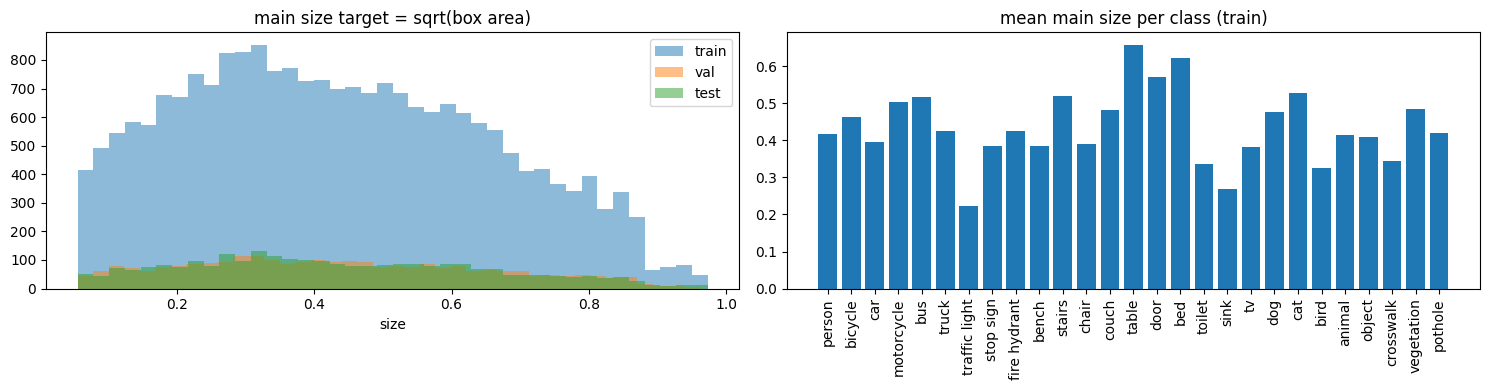

In [5]:
# CELL 4 - INDEX: list every image with its main class (the folder), its main size, and its MULTI-LABEL targets (which of the 27 classes are in the picture and how big each one is). No cache files, so nothing can go stale.
def read_areas(txt_path):   # label file -> the largest box area of every class (27 numbers, 0 = no box of that class)
    a = np.zeros(NC, dtype=np.float32)   # start with nothing
    for line in Path(txt_path).read_text().splitlines():   # each box line: class cx cy w h
        v = line.split()   # split into fields
        if len(v) < 5:   # skip empty or broken lines
            continue   # next line
        a[int(v[0])] = max(a[int(v[0])], float(v[3]) * float(v[4]))   # keep the largest box area of that class
    return a   # areas per class

def size_target(txt_path, cid):   # label file -> apparent size of the MAIN object = sqrt(area) of its largest box
    a = read_areas(txt_path)   # largest box area per class
    return math.sqrt(a[cid] if a[cid] > 0 else a.max())   # use the main class's box (fallback: the largest box of any class)

SRC_OF = {}   # (split, class folder, file name) -> the source dataset the picture came from
if (Path(DATA) / 'manifest.csv').exists():   # the dataset notebook writes this table
    with open(Path(DATA) / 'manifest.csv') as f:   # open it
        for r in csv.DictReader(f):   # one row per picture
            SRC_OF[(r['split'], folder_name(r['cls']), r['file'])] = r['src']   # remember its source
else:   # no table: every class is treated as labelled in every picture
    print('WARNING: manifest.csv not found, so every class is treated as fully labelled in every picture')   # tell the user

def build_index(split):   # all images of one split
    paths, labels, sizes, areas, srcs = [], [], [], [], []   # parallel lists
    for cid, cname in enumerate(CLASS_LIST):   # every class folder
        for jp in sorted((Path(DATA) / split / folder_name(cname)).glob('*.jpg')):   # every image in it
            paths.append(str(jp))   # image path
            labels.append(cid)   # main class = the folder
            sizes.append(size_target(jp.with_suffix('.txt'), cid))   # main size from its label file
            areas.append(read_areas(jp.with_suffix('.txt')))   # largest box per class (for the multi-label targets)
            srcs.append(SRC_OF.get((split, folder_name(cname), jp.name), ''))   # source dataset ('' if unknown)
    return np.array(paths), np.array(labels, dtype=np.int32), np.array(sizes, dtype=np.float32), np.array(areas, dtype=np.float32), np.array(srcs)   # as arrays

INDEX, AREAS, SRCS = {}, {}, {}   # (paths, main labels, main sizes), box areas per class, source names
for s in ('train', 'val', 'test'):   # every split
    p_, l_, z_, a_, c_ = build_index(s)   # read it
    INDEX[s], AREAS[s], SRCS[s] = (p_, l_, z_), a_, c_   # store the parts

all_src = np.concatenate([SRCS[s] for s in INDEX]); all_area = np.concatenate([AREAS[s] for s in INDEX])   # every picture of every split
SRC_CLASSES = {}   # source -> the classes that source really labels
for src in sorted(set(all_src)):   # each source dataset
    n_with = (all_area[all_src == src] > 0).sum(0)   # in how many of its pictures each class has a box
    SRC_CLASSES[src] = np.where(n_with >= SRC_MIN_IMAGES)[0]   # a class counts as 'labelled by this source' when it shows up often enough
print('classes each source dataset labels (the other classes are unknown there, not absent):')   # explanation
for src, cl in SRC_CLASSES.items():   # one line per source
    print(f"  {src or '(unknown)':10s} {len(cl):2d} classes: " + (', '.join(CLASS_LIST[c] for c in cl) if len(cl) <= 8 else f'{CLASS_LIST[cl[0]]}, {CLASS_LIST[cl[1]]}, ... {CLASS_LIST[cl[-1]]}'))   # short list

MIN_AREA = np.array([max(MULTI_MIN_AREA, (CLASS_INFO[n][1] / (IGNORE_BEYOND_M * 2 * TAN_HALF)) ** 2) for n in CLASS_LIST])   # per class: the box area it would have at IGNORE_BEYOND_M metres (cell 2 formula); smaller boxes are silent far objects, so they are ignored, not counted as present or absent
SPECIALIST = [c for c in range(NC) if any(len(cl) == 1 and cl[0] == c for cl in SRC_CLASSES.values())]   # classes that some source labels ON ITS OWN (stairs, pothole, crosswalk, door ...)
print('ignore area per class (share of the picture; boxes below it are neither present nor absent): ' + '  '.join(f'{CLASS_LIST[c]}={MIN_AREA[c]:.3f}' for c in range(NC)))   # show it
print('specialist classes (get weak negatives in pictures of other sources):', [CLASS_LIST[c] for c in SPECIALIST])   # show them

MULTI = {}   # split -> dict(pres, known, lossw, size), each (pictures x 27)
for s in INDEX:   # every split
    a, lab, n = AREAS[s], INDEX[s][1], len(INDEX[s][1])   # box areas, main labels, number of pictures
    pres = a >= MIN_AREA[None, :]   # an object counts as present when its largest box is big enough to be audible (per-class limit)
    pres[np.arange(n), lab] = True   # the main object is always present
    tiny = (a > 0) & ~pres   # real but very small objects: not trusted either way, so ignored
    known = np.zeros(a.shape, dtype=bool)   # which classes the picture's source dataset labels
    for src in set(SRCS[s]):   # each source in this split
        rows = SRCS[s] == src   # its pictures
        known[rows] = True if (src == '' or src not in SRC_CLASSES) else np.isin(np.arange(NC), SRC_CLASSES[src])[None, :]   # all classes if the source is unknown, else only its own
    known = (known & ~tiny) | pres   # tiny objects are ignored; present objects are always known
    size = np.sqrt(a).astype(np.float32)   # size of every class's largest box
    size[np.arange(n), lab] = INDEX[s][2]   # the main object keeps its original size target
    lossw = known.astype(np.float32)   # weight of every entry in the TRAINING loss (1 = known, 0 = ignored)
    for ns_, nc_ in NOISY_LABELS:   # unreliable (source, class) pairs
        rows_n = SRCS[s] == ns_   # pictures of that source
        c_n = CLASS_LIST.index(nc_)   # the class
        lossw[rows_n & ~pres[:, c_n], c_n] = WEAK_NEG_W   # absent: weak negative
        lossw[rows_n & pres[:, c_n], c_n] = 1.0   # present: a real positive
        known[rows_n, c_n] = False   # and the metrics ignore the whole entry
    for c in SPECIALIST:   # specialist classes: a picture of another source almost never contains them, even if that source does not label them
        weak = (~known[:, c]) & (a[:, c] == 0)   # unknown and no box at all
        lossw[weak, c] = WEAK_NEG_W   # weak 'absent' label (the metrics still ignore these entries)
    for c in range(NC):   # every class
        if CLASS_INFO[CLASS_LIST[c]][2] == 2:   # hazard level 2 = danger
            lossw[:, c] *= DANGER_LOSS_W   # count its errors more in the training loss (validation and the metrics are not affected)
    MULTI[s] = dict(pres=pres.astype(np.float32), known=known.astype(np.float32), lossw=lossw, size=size)   # store as float arrays

for s in INDEX:   # print a summary per split
    p, l, z = INDEX[s]   # its arrays
    k = MULTI[s]['pres'].sum(1)   # classes present per picture
    print(f'{s:5s} {len(p):6d} images | main size mean {z.mean():.3f} min {z.min():.3f} max {z.max():.3f} | classes per picture: mean {k.mean():.2f}, two or more in {float((k >= 2).mean()) * 100:.0f}% | unknown (ignored) entries {float((1 - MULTI[s]["known"]).mean()) * 100:.0f}%')   # counts and shares
pos = MULTI['train']['pres'].sum(0).astype(int)   # training pictures that contain each class
print('pictures containing each class (train): ' + '  '.join(f'{CLASS_LIST[c]}={pos[c]}' for c in np.argsort(pos)))   # rarest first

if MIN_TRAIN_SIZE > 0:   # optional clean-up of the TRAINING split only
    keep = INDEX['train'][2] >= MIN_TRAIN_SIZE   # pictures whose main object is big enough to be the clear subject
    print(f"training images kept: {int(keep.sum())} of {len(keep)} (val and test are not filtered)")   # how much was removed
    INDEX['train'] = tuple(a[keep] for a in INDEX['train'])   # apply the filter to paths, labels and sizes
    MULTI['train'] = {k: v[keep] for k, v in MULTI['train'].items()}   # and to the multi-label targets

mean_size = [INDEX['train'][2][INDEX['train'][1] == c].mean() for c in range(NC)]   # mean main size per class
fig, ax = plt.subplots(1, 2, figsize=(15, 4))   # two charts side by side
for s in INDEX:   # one histogram per split
    ax[0].hist(INDEX[s][2], bins=40, alpha=0.5, label=s)   # distribution of main size targets
ax[0].set_title('main size target = sqrt(box area)'); ax[0].set_xlabel('size'); ax[0].legend()   # title, axis label, legend
ax[1].bar(range(NC), mean_size)   # mean main size of each class
ax[1].set_xticks(range(NC)); ax[1].set_xticklabels(CLASS_LIST, rotation=90); ax[1].set_title('mean main size per class (train)')   # class names under the bars
plt.tight_layout(); plt.show()   # draw both charts


### Teacher stage (only when no teacher file exists yet)
Distillation needs a large trained model. Cell 4a checks Drive; if there is no teacher, the cells marked **TEACHER STAGE** train one (the large settings, about 3-4 hours on a T4), save it to Drive and then switch back to the compact settings. If a teacher is already on Drive, these cells do nothing and run in a second.

In [6]:
# CELL 4a - IS A TEACHER NEEDED? Distillation needs a large trained model. If none is saved on Drive yet (TEACHER_PATH), this notebook trains one first (cells 5-8 run once with the LARGE settings), saves it to Drive, and then trains the compact model from it. If one is already there, that training is skipped.
KD_W_CFG = KD_W   # remember the wanted distillation weight (it is switched off while the teacher itself is trained)
for s_ in ('train', 'val', 'test'):   # all three splits
    MULTI[s_]['tprob'] = MULTI[s_]['pres'].copy()   # a dummy 'teacher answer' so the pipeline has the same shape everywhere (replaced in cell 4c)
TEACHER_NEEDED = bool(USE_TEACHER in (True, 'auto') and TRAIN_TEACHER and not Path(TEACHER_PATH).exists())   # train a teacher only when one is wanted, allowed and missing
if TEACHER_NEEDED:   # no teacher on Drive yet
    print(f'No teacher found at {TEACHER_PATH}.')   # say so
    print(f'The next cells (marked TEACHER STAGE) first train a LARGE model ({TEACHER_CFG["ALPHA"]} width, {SRC_SIZE} px; roughly 3-4 hours on a T4), save it to Drive, and then continue with the compact model.')   # what happens
    print('If the session is interrupted after the teacher was saved, run all cells again: the teacher stage is then skipped.')   # resume hint
elif Path(TEACHER_PATH).exists() and USE_TEACHER in (True, 'auto'):   # a teacher exists
    print('Teacher found on Drive:', TEACHER_PATH, '-> the teacher stage is skipped.')   # nothing to train
else:   # distillation switched off
    print('Distillation is off (USE_TEACHER = False or TRAIN_TEACHER = False and no teacher file): the compact model trains on the real labels only.')   # say so


Teacher found on Drive: /content/drive/MyDrive/IRP/teacher/float_model.keras -> the teacher stage is skipped.


In [7]:
# CELL - TEACHER STAGE (start): switch the settings to the LARGE model and a separate output folder. Only does something when cell 4a said a teacher is needed.
if TEACHER_NEEDED:   # skipped when a teacher already exists
    TEACHER_CFG['IMG_SIZE'] = SRC_SIZE   # the teacher reads the pictures at their stored size (no shrinking)
    STUDENT_CFG = {k: globals()[k] for k in TEACHER_CFG}   # remember the compact settings that are about to be replaced
    globals().update(TEACHER_CFG)   # switch to the large-model settings (width, input size, heads, epochs, no distillation)
    OUT_STUDENT = OUT   # remember the compact model's output folder
    OUT = f'{OUT}/teacher'   # the teacher writes into its own folder
    os.makedirs(OUT, exist_ok=True)   # create it
    print('TEACHER STAGE: width', ALPHA, '| input', IMG_SIZE, '| epochs', EPOCHS_HEAD, '+', EPOCHS_FINE, '| output', OUT)   # confirm the switch


In [8]:
# CELL (TEACHER STAGE: runs only if a teacher has to be trained) 5 - INPUT PIPELINE (tf.data): reads images from local disk in batches, augments the training images (colour, blur, noise, JPEG quality, mirror, small shift), scales pixels to -1..1 and attaches the multi-label targets.
if TEACHER_NEEDED:   # skipped when a teacher already exists
    # No zoom / crop augmentation on purpose: it would change how big the object looks and so corrupt the size (distance) target.
    def read_image(path):   # file path -> uint8 RGB image of IMG_SIZE x IMG_SIZE
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)   # read and decode the JPEG as RGB
        if SRC_SIZE != IMG_SIZE:   # only when the model input differs from the stored size
            img = tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE], antialias=True), tf.uint8)   # resize the whole square picture (boxes are fractions, so they stay valid)
        return img   # the image

    def to_input(x01):   # picture scaled 0..1 -> -1..1 (what MobileNetV2 expects); the same rule is used on the device
        return x01 * 2.0 - 1.0   # linear rescale

    BLUR_K = tf.constant([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]]) / 16.0   # 3 x 3 Gaussian blur kernel
    BLUR_K = tf.tile(BLUR_K[:, :, None, None], [1, 1, 3, 1])   # one copy per colour channel (depthwise filter)
    SHIFT_PX = int(0.04 * IMG_SIZE)   # largest sideways / vertical shift: 4 percent of the picture

    def augment(x01):   # random changes that look like real camera conditions (none of them changes the object's size or class)
        x01 = tf.image.random_brightness(x01, 0.30)   # lighter or darker
        x01 = tf.image.random_contrast(x01, 0.6, 1.4)   # more or less contrast
        x01 = tf.image.random_saturation(x01, 0.6, 1.4)   # more or less colourful
        x01 = tf.image.random_hue(x01, 0.06)   # slight colour shift
        x01 = tf.image.random_flip_left_right(x01)   # mirror (left/right does not matter for the class or the size)
        x01 = tf.clip_by_value(x01, 0.0, 1.0)   # keep pixel values inside 0..1 before the next steps
        x01 = tf.image.random_jpeg_quality(x01, 40, 100)   # compression artefacts like a cheap camera
        blurred = tf.nn.depthwise_conv2d(x01[None], BLUR_K, [1, 1, 1, 1], 'SAME')[0]   # a slightly blurred copy (out-of-focus / motion)
        x01 = tf.where(tf.random.uniform([]) < 0.3, blurred, x01)   # blur 30 percent of the pictures
        x01 = x01 + tf.random.normal(tf.shape(x01), stddev=tf.random.uniform([], 0.0, 0.03))   # a little sensor noise
        if SHIFT_PX > 0:   # small random shift (not a zoom, so the object keeps its size)
            x01 = tf.pad(x01, [[SHIFT_PX, SHIFT_PX], [SHIFT_PX, SHIFT_PX], [0, 0]], constant_values=114.0 / 255.0)   # pad with the same grey as the dataset letterbox
            x01 = tf.image.random_crop(x01, [IMG_SIZE, IMG_SIZE, 3])   # cut a random window of the original size
        return tf.clip_by_value(x01, 0.0, 1.0)   # keep pixel values inside 0..1

    def make_example(path, label, pres, known, szv, tp, train):   # one picture and its targets -> (model input, targets)
        x = tf.cast(read_image(path), tf.float32) / 255.0   # pixels 0..1
        if train:   # augmentation only for training images
            x = augment(x)   # random changes
        y_cls = tf.stack([pres, known, tf.one_hot(label, NC), tp], axis=0)   # 4 x 27: present (1/0), known (1 = counts in the loss, 0 = ignored), main class (one-hot, only for the top-1 comparison), the teacher's soft answer (only used when KD_W > 0)
        y_size = tf.stack([szv, pres], axis=-1)   # 27 x 2: size of each class's largest box, and whether that class is present (only present objects count)
        return to_input(x), {'cls': y_cls, 'size': y_size}   # image and both target blocks

    def make_ds(split, train):   # a batched tf.data pipeline for one split
        paths, labels, _ = INDEX[split]   # paths and main labels from cell 4
        M = MULTI[split]   # the multi-label targets
        ds = tf.data.Dataset.from_tensor_slices((paths, labels, M['pres'], M['lossw'] if train else M['known'], M['size'], M['tprob']))   # one element per image (training uses the loss weights incl. weak negatives, val and test only the known entries)
        if train:   # shuffle only the training data
            ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)   # new order every epoch (only file names and small arrays are held in memory)
        ds = ds.map(lambda p, l, pr, kn, sz, tp: make_example(p, l, pr, kn, sz, tp, train), num_parallel_calls=tf.data.AUTOTUNE)   # decode + augment in parallel
        return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)   # batches, prepared ahead of the GPU

    train_ds, val_ds, test_ds = make_ds('train', True), make_ds('val', False), make_ds('test', False)   # the three pipelines
    x_demo, y_demo = next(iter(train_ds))   # look at one batch
    print('batch:', x_demo.shape, 'pixel range', float(tf.reduce_min(x_demo)), 'to', float(tf.reduce_max(x_demo)), '| targets:', {k: v.shape for k, v in y_demo.items()})   # shapes and range


In [9]:
# CELL (TEACHER STAGE: runs only if a teacher has to be trained) 6 - MODEL: MobileNetV2 backbone + three SSDLite-style heads (40x40, 20x20, 10x10 features) -> two outputs: for EVERY class a presence score and a size. Also the losses and metrics for several objects per picture.
if TEACHER_NEEDED:   # skipped when a teacher already exists
    FEATURE_LAYERS = ['block_6_expand_relu', 'block_13_expand_relu', LARGE_LAYER]   # backbone layers at three scales (fine, medium, coarse)

    REG = keras.regularizers.l2(L2_WEIGHT)   # weight decay used on the new layers

    def head(x, name):   # one SSDLite-style head: depthwise 3x3 + pointwise 1x1, then average and max over the picture
        x = keras.layers.DepthwiseConv2D(3, padding='same', use_bias=False, name=f'{name}_dw')(x)   # cheap spatial filter
        x = keras.layers.BatchNormalization(name=f'{name}_dw_bn')(x)   # normalise (folds into the conv when quantized)
        x = keras.layers.ReLU(6.0, name=f'{name}_dw_relu')(x)   # ReLU6 is friendly to int8
        x = keras.layers.Conv2D(HEAD_CH, 1, use_bias=False, kernel_regularizer=REG, name=f'{name}_pw')(x)   # mix channels down to HEAD_CH
        x = keras.layers.BatchNormalization(name=f'{name}_pw_bn')(x)   # normalise
        x = keras.layers.ReLU(6.0, name=f'{name}_pw_relu')(x)   # ReLU6 again
        avg = keras.layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)   # average over the picture: what is there on the whole
        mx = keras.layers.GlobalMaxPooling2D(name=f'{name}_gmp')(x)   # strongest response anywhere: a small object still shows up here, the average would wash it out
        return keras.layers.Concatenate(name=f'{name}_pool')([avg, mx]), x   # 2 x HEAD_CH pooled numbers per head, and the feature map itself (used by the per-position presence scores)

    def build_model(alpha=ALPHA, weights=WEIGHTS):   # build the whole network as ONE flat graph (needed for quantization-aware training and pruning)
        inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')   # input: pictures already scaled to -1..1
        base = keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=alpha)   # the backbone
        for layer in base.layers:   # start with the backbone frozen
            layer.trainable = False   # (phase 1 trains only the new layers)
        outs = [head(base.get_layer(n).output, t) for n, t in zip(FEATURE_LAYERS, ('small', 'med', 'large'))]   # three heads on three scales
        pooled = [o[0] for o in outs]   # the pooled summaries
        x = keras.layers.Concatenate(name='merge')(pooled)   # join the three summaries
        x = keras.layers.Dense(FC1_UNITS, use_bias=False, kernel_regularizer=REG, name='fc1')(x)   # first fully connected layer
        x = keras.layers.BatchNormalization(name='fc1_bn')(x)   # normalise
        x = keras.layers.ReLU(6.0, name='fc1_relu')(x)   # ReLU6
        x = keras.layers.Dropout(DROP1, name='fc1_drop')(x)   # drop part of the units while training (less over-fitting)
        x = keras.layers.Dense(FC2_UNITS, use_bias=False, kernel_regularizer=REG, name='fc2')(x)   # second fully connected layer
        x = keras.layers.BatchNormalization(name='fc2_bn')(x)   # normalise
        x = keras.layers.ReLU(6.0, name='fc2_relu')(x)   # ReLU6
        x = keras.layers.Dropout(DROP2, name='fc2_drop')(x)   # drop part of the units while training
        cls_fc = keras.layers.Dense(NC, kernel_regularizer=REG, name='cls_fc')(x)   # presence logits from the global summary
        pos = [keras.layers.Conv2D(NC, 1, kernel_regularizer=REG, bias_initializer=keras.initializers.Constant(-1.0), name=f'pos_{t}')(o[1]) for o, t in zip(outs, ('small', 'med', 'large'))]   # a presence score for EVERY POSITION of the 40 x 40, 20 x 20 and 10 x 10 maps: a small object only has to light up one position
        pos = [keras.layers.GlobalMaxPooling2D(name=f'pos_{t}_max')(p) for p, t in zip(pos, ('small', 'med', 'large'))]   # the best position of each map counts (works with image-level labels)
        best = keras.layers.Maximum(name='pos_best')(pos)   # the best of the three scales
        cls = keras.layers.Add(name='cls')([cls_fc, best])   # output 1: one presence score (logit) per class = global score + best-position score; the classes are judged independently (sigmoid, not softmax)
        m = keras.layers.Conv2D(SIZE_MAP_CH, 1, use_bias=False, kernel_regularizer=REG, name='size_map')(base.get_layer(LARGE_LAYER).output)   # squeeze the coarse 10 x 10 feature map to a few channels (keeps the spatial layout)
        m = keras.layers.BatchNormalization(name='size_map_bn')(m)   # normalise
        m = keras.layers.ReLU(6.0, name='size_map_relu')(m)   # ReLU6
        m = keras.layers.Flatten(name='size_flat')(m)   # keep every position: WHERE the object is and HOW MUCH of the picture it covers
        s = keras.layers.Concatenate(name='size_join')([x, m])   # join the global summary with the spatial map
        s = keras.layers.Dense(SIZE_FC_UNITS, kernel_regularizer=REG, name='size_fc')(s)   # small branch for the size outputs
        s = keras.layers.ReLU(6.0, name='size_relu')(s)   # ReLU6
        s = keras.layers.Dense(NC, activation='sigmoid', name='size_dense')(s)   # output 2 before reshaping: the apparent size (0..1) of every class
        size = keras.layers.Reshape((NC, 1), name='size')(s)   # shape 27 x 1, so the device can tell it apart from the 27 presence scores
        model = keras.Model(inp, [cls, size], name='fyp_navigation')   # the full model
        bb_bn = [l.name for l in base.layers if isinstance(l, keras.layers.BatchNormalization)]   # names of the backbone's batch-norm layers
        return model, bb_bn   # model and those names

    def presence_loss(y_true, y_pred):   # asymmetric loss for 'is this class in the picture?', counted only where the label is known (easy absent classes count much less, so the hard ones get the attention)
        t, w = y_true[:, 0, :], y_true[:, 1, :]   # target (1 = present) and weight (1 = known, 0 = unknown or ignored, 0.3 = weak negative)
        t = t * (1.0 - LABEL_SMOOTH) + 0.5 * LABEL_SMOOTH   # slightly softened targets
        x = tf.clip_by_value(y_pred, -15.0, 15.0)   # keep the scores in a safe range: a saturated sigmoid would give an infinite gradient and turn the whole training into NaN
        pos = t * tf.math.log_sigmoid(x)   # log-likelihood term of the present classes (computed in the numerically safe way)
        if ASL_GAMMA_POS > 0:   # only when present classes should also be focused (0 = skip, a power of zero has a broken gradient)
            pos = pos * tf.pow(tf.sigmoid(-x) + 1e-7, ASL_GAMMA_POS)   # down-weight present classes that are already easy
        pn = tf.maximum(tf.sigmoid(x) - ASL_CLIP, 0.0)   # for absent classes a probability below ASL_CLIP costs nothing (this also protects against wrong 'absent' labels)
        neg = (1.0 - t) * tf.pow(pn + 1e-7, ASL_GAMMA_NEG) * tf.math.log(tf.maximum(1.0 - pn, 1e-7))   # log-likelihood term of the absent classes, down-weighted when they are already easy (small p)
        w = w * (1.0 + (POS_WEIGHT - 1.0) * y_true[:, 0, :])   # present objects count POS_WEIGHT times (1.0 = no extra weight)
        hard = -ASL_SCALE * tf.reduce_sum((pos + neg) * w, axis=-1) / tf.maximum(tf.reduce_sum(w, axis=-1), 1.0)   # the loss against the real labels: weighted mean per picture, scaled so it stays comparable with the size loss
        soft = ASL_SCALE * (KD_T ** 2) * tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true[:, 3, :], logits=x / KD_T), axis=-1)   # the loss against the teacher's softened answers, over ALL 27 classes (it also fills in classes whose label is unknown)
        return (1.0 - KD_W) * hard + KD_W * soft   # mix of the two (KD_W = 0 gives only the real labels)

    def size_loss(y_true, y_pred):   # Huber loss of the size, counted only for the objects that are present
        t, v = y_true[:, :, 0], y_true[:, :, 1]   # true size and 'present' flag of every class
        h = keras.losses.huber(t[..., None], y_pred, delta=0.1)   # error of every class (shape: pictures x 27)
        return tf.reduce_sum(h * v, axis=-1) / tf.maximum(tf.reduce_sum(v, axis=-1), 1.0)   # mean over the present objects

    class MaskedF1(keras.metrics.Metric):   # F1 score of the presence decisions at probability 0.5, over the known entries
        def __init__(self, name='f1', **kw):   # create the three running counters
            super().__init__(name=name, **kw)   # base class
            self.tp = self.add_weight(name='tp', initializer='zeros')   # correctly found objects
            self.fp = self.add_weight(name='fp', initializer='zeros')   # false alarms
            self.fn = self.add_weight(name='fn', initializer='zeros')   # missed objects
        def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
            t, w = y_true[:, 0, :], y_true[:, 1, :]   # target and 'known' weight
            p = tf.cast(y_pred > 0.0, tf.float32)   # a logit above 0 means a probability above 0.5
            self.tp.assign_add(tf.reduce_sum(w * t * p)); self.fp.assign_add(tf.reduce_sum(w * (1 - t) * p)); self.fn.assign_add(tf.reduce_sum(w * t * (1 - p)))   # count
        def result(self):   # the score so far
            return 2 * self.tp / tf.maximum(2 * self.tp + self.fp + self.fn, 1.0)   # F1 = 2tp / (2tp + fp + fn)
        def reset_state(self):   # start a new epoch
            for v in (self.tp, self.fp, self.fn):   # each counter
                v.assign(0.0)   # back to zero

    class Top1(keras.metrics.Metric):   # old-style accuracy: is the strongest score the main object's class? (only to compare with the earlier single-label models)
        def __init__(self, name='top1', **kw):   # create the counters
            super().__init__(name=name, **kw)   # base class
            self.hit = self.add_weight(name='hit', initializer='zeros')   # correct pictures
            self.n = self.add_weight(name='n', initializer='zeros')   # all pictures
        def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
            ok = tf.equal(tf.argmax(y_true[:, 2, :], axis=-1), tf.argmax(y_pred, axis=-1))   # strongest score = main class?
            self.hit.assign_add(tf.reduce_sum(tf.cast(ok, tf.float32))); self.n.assign_add(tf.cast(tf.shape(ok)[0], tf.float32))   # count
        def result(self):   # the score so far
            return self.hit / tf.maximum(self.n, 1.0)   # share correct
        def reset_state(self):   # start a new epoch
            self.hit.assign(0.0); self.n.assign(0.0)   # back to zero

    class SizeMAE(keras.metrics.Metric):   # mean absolute size error over the present objects
        def __init__(self, name='mae', **kw):   # create the counters
            super().__init__(name=name, **kw)   # base class
            self.err = self.add_weight(name='err', initializer='zeros')   # summed error
            self.n = self.add_weight(name='n', initializer='zeros')   # number of objects
        def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
            t, v = y_true[:, :, 0], y_true[:, :, 1]   # true size and 'present' flag
            self.err.assign_add(tf.reduce_sum(tf.abs(t - y_pred[:, :, 0]) * v)); self.n.assign_add(tf.reduce_sum(v))   # accumulate
        def result(self):   # the score so far
            return self.err / tf.maximum(self.n, 1.0)   # mean error
        def reset_state(self):   # start a new epoch
            self.err.assign(0.0); self.n.assign(0.0)   # back to zero

    def compile_model(m, lr):   # attach optimizer, losses and metrics
        m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=CLIPNORM),   # Adam with gradient clipping
                  loss={'cls': presence_loss, 'size': size_loss},   # presence loss and size loss
                  loss_weights={'cls': 1.0, 'size': SIZE_LOSS_W},   # how much each loss counts
                  metrics={'cls': [MaskedF1(), Top1()], 'size': [SizeMAE()]})   # F1 of the presence decisions, old-style top-1, size error

    model, BACKBONE_BN = build_model()   # build it
    compile_model(model, LR_HEAD)   # compile for phase 1
    n_params = model.count_params()   # total number of weights
    n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)   # weights trained in phase 1
    print(f'parameters: {n_params:,} total, {n_train:,} trainable now | float32 ~{n_params * 4 / 1e6:.1f} MB, int8 ~{n_params / 1e6:.1f} MB')   # size estimate


In [10]:
# CELL (TEACHER STAGE: runs only if a teacher has to be trained) 7 - TRAINING PHASE 1: train only the new heads while the pretrained backbone stays frozen (this runs on the GPU).
if TEACHER_NEEDED:   # skipped when a teacher already exists
    def callbacks_for(ckpt, lr_patience, stop_patience):   # early stopping, learning-rate reduction and best-weights saving
        return [keras.callbacks.TerminateOnNaN(),   # stop at once if the loss ever becomes NaN (instead of wasting hours on a broken run)
                keras.callbacks.EarlyStopping(monitor='val_cls_f1', mode='max', patience=stop_patience, restore_best_weights=True),   # stop when the validation F1 stops improving
                keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=lr_patience, min_lr=1e-8, verbose=1),   # halve the learning rate when val loss stalls
                keras.callbacks.ModelCheckpoint(ckpt, monitor='val_cls_f1', mode='max', save_best_only=True, save_weights_only=True, verbose=0)]   # keep the best weights on disk

    t0 = time.time()   # start the clock
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks_for(f'{OUT}/phase1_best.weights.h5', 2, 4), verbose=2)   # train
    model.load_weights(f'{OUT}/phase1_best.weights.h5')   # go back to the best epoch
    r1 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
    print(f"phase 1 done in {(time.time() - t0) / 60:.1f} min | val F1 {r1['cls_f1']:.4f} | val size error {r1['size_mae']:.4f}")   # result


In [11]:
# CELL (TEACHER STAGE: runs only if a teacher has to be trained) 8 - TRAINING PHASE 2: unfreeze the whole network and fine-tune with a very small learning rate; then plot the curves and save the float model.
if TEACHER_NEEDED:   # skipped when a teacher already exists
    for layer in model.layers:   # every layer
        layer.trainable = True   # unfreeze
    for layer in model.layers:   # then
        if layer.name in BACKBONE_BN:   # keep the backbone's batch-norm layers frozen
            layer.trainable = False   # (steadier fine-tuning and better int8 behaviour)
    compile_model(model, LR_FINE)   # re-compile so the change takes effect
    t0 = time.time()   # start the clock
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, callbacks=callbacks_for(f'{OUT}/best.weights.h5', FINE_LR_PATIENCE, FINE_STOP_PATIENCE), verbose=2)   # fine-tune
    model.load_weights(f'{OUT}/best.weights.h5')   # go back to the best epoch
    r2 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
    print(f"phase 2 done in {(time.time() - t0) / 60:.1f} min | val F1 {r2['cls_f1']:.4f} | val size error {r2['size_mae']:.4f}")   # result
    model.save(f'{OUT}/float_model.keras')   # save the full float model
    model.save_weights(f'{OUT}/float.weights.h5')   # and just its weights

    h1, h2 = hist1.history, hist2.history   # the two training logs
    cut = len(h1['loss'])   # epoch where fine-tuning starts
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))   # three charts
    ax[0].plot(h1['cls_f1'] + h2['cls_f1'], label='train'); ax[0].plot(h1['val_cls_f1'] + h2['val_cls_f1'], label='val')   # presence F1
    ax[0].set_title('presence F1 (threshold 0.5)')   # chart title
    ax[1].plot(h1['loss'] + h2['loss'], label='train'); ax[1].plot(h1['val_loss'] + h2['val_loss'], label='val')   # total loss
    ax[1].set_title('total loss')   # chart title
    ax[2].plot(h1['size_mae'] + h2['size_mae'], label='train'); ax[2].plot(h1['val_size_mae'] + h2['val_size_mae'], label='val')   # size error
    ax[2].set_title('size error (mean absolute)')   # chart title
    for a in ax:   # decorate all three
        a.axvline(cut, color='red', linestyle='--', label='fine-tuning starts'); a.set_xlabel('epoch'); a.grid(True); a.legend()   # phase marker, label, grid, legend
    plt.tight_layout(); plt.savefig(f'{OUT}/training_curves.png', dpi=130); plt.show()   # save and show


In [7]:
# CELL - TEACHER STAGE (end): save the trained large model to Drive, free the memory and switch back to the compact settings.
if TEACHER_NEEDED:   # skipped when no teacher was trained
    Path(TEACHER_PATH).parent.mkdir(parents=True, exist_ok=True)   # make the Drive folder
    shutil.copy(f'{OUT}/float_model.keras', TEACHER_PATH)   # keep the teacher on Drive (a later run can skip this stage)
    print('teacher saved to Drive:', TEACHER_PATH, f'({Path(TEACHER_PATH).stat().st_size / 1e6:.1f} MB)')   # where it is
    globals().update(STUDENT_CFG)   # back to the compact settings
    OUT = OUT_STUDENT   # back to the compact output folder
    for name_ in ('model', 'train_ds', 'val_ds', 'test_ds', 'hist1', 'hist2'):   # the teacher's objects
        globals().pop(name_, None)   # drop them
    keras.backend.clear_session()   # free the GPU memory and the old graph
    import gc; gc.collect()   # and the Python memory
    print('back to the compact settings: width', ALPHA, '| input', IMG_SIZE)   # confirm the switch back
KD_W = KD_W_CFG   # the compact model uses the wanted distillation weight


### Teacher answers
The teacher answers for every training picture; its softened probabilities become extra targets for the compact model.

In [8]:
# CELL 4c - TEACHER ANSWERS (knowledge distillation): the large, trained model answers for every training picture, and its soft answers become extra targets for the compact model. This is the usual way to make a tiny network more accurate without making it bigger.
if USE_TEACHER is True or (USE_TEACHER == 'auto' and Path(TEACHER_PATH).exists()):   # a teacher is wanted and available
    teacher = keras.models.load_model(TEACHER_PATH, compile=False)   # load the large float model (no losses needed to predict)
    T_SIZE = int(teacher.input_shape[1])   # the picture size the teacher expects
    print('teacher loaded:', TEACHER_PATH, '| input', T_SIZE, '| parameters', f'{teacher.count_params() / 1e6:.2f}M')   # what we got

    def read_teacher(path):   # file -> picture for the teacher, scaled -1..1
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)   # read and decode as RGB
        if SRC_SIZE != T_SIZE:   # the stored size differs from the teacher input
            img = tf.cast(tf.image.resize(img, [T_SIZE, T_SIZE], antialias=True), tf.uint8)   # resize with anti-aliasing
        return tf.cast(img, tf.float32) / 127.5 - 1.0   # the same scaling as the models use

    def teacher_logits(split):   # the teacher's presence scores for every picture of a split, averaged over the picture and its mirror image (cleaner answers than one view)
        ds_ = tf.data.Dataset.from_tensor_slices(INDEX[split][0]).map(read_teacher, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE)   # batches of pictures
        outs_ = []   # one result per view
        for flip_ in (False, True):   # normal picture, then mirrored
            d_ = ds_.map(lambda x: tf.reverse(x, [2])) if flip_ else ds_   # mirror = reverse the width axis
            o_ = teacher.predict(d_, verbose=0)   # run the teacher
            outs_.append(np.asarray(o_[teacher.output_names.index('cls')] if isinstance(o_, list) else o_, dtype=np.float32))   # take the presence output
        return (outs_[0] + outs_[1]) / 2.0   # average of the two views

    def quick_f1(lg, split):   # precision / recall / F1 of the teacher at probability 0.5 on the known entries
        M_ = MULTI[split]; k_ = M_['known'] > 0; pr_ = (lg > 0) & k_; y_ = (M_['pres'] > 0) & k_   # decisions and truth
        tp_, fp_, fn_ = (pr_ & y_).sum(), (pr_ & ~y_).sum(), (~pr_ & y_ & k_).sum()   # counts
        return tp_ / max(tp_ + fp_, 1), tp_ / max(tp_ + fn_, 1), 2 * tp_ / max(2 * tp_ + fp_ + fn_, 1)   # precision, recall, F1

    lg_tr, lg_va = teacher_logits('train'), teacher_logits('val')   # answers for the training and validation pictures
    print('teacher on validation: precision %.3f recall %.3f F1 %.3f' % quick_f1(lg_va, 'val'))   # how good the teacher is on unseen pictures
    print('teacher on training  : precision %.3f recall %.3f F1 %.3f   (much higher than validation = the teacher memorised the training set, its answers are then close to the labels)' % quick_f1(lg_tr, 'train'))   # and on the pictures it learned from
    MULTI['train']['tprob'] = (1.0 / (1.0 + np.exp(-lg_tr / KD_T))).astype(np.float32)   # softened probabilities become the soft targets
    del teacher   # free the memory
else:   # no teacher
    KD_W = 0.0   # the loss then uses only the real labels
    print('no teacher available -> training without distillation (KD_W = 0)')   # explain


teacher loaded: /content/drive/MyDrive/IRP/teacher/float_model.keras | input 320 | parameters 3.79M
teacher on validation: precision 0.794 recall 0.833 F1 0.813
teacher on training  : precision 0.868 recall 0.918 F1 0.893   (much higher than validation = the teacher memorised the training set, its answers are then close to the labels)


## Part C - Compact model and training (GPU)
The input pipeline and the compact model, now with the compact settings. MobileNetV2 backbone with three SSDLite-style heads and two outputs: 27 presence scores and 27 sizes (shape 27 x 1). The presence loss is an asymmetric loss mixed with the teacher's soft answers.

In [9]:
# CELL 5 - INPUT PIPELINE (tf.data): reads images from local disk in batches, augments the training images (colour, blur, noise, JPEG quality, mirror, small shift), scales pixels to -1..1 and attaches the multi-label targets.
# No zoom / crop augmentation on purpose: it would change how big the object looks and so corrupt the size (distance) target.
def read_image(path):   # file path -> uint8 RGB image of IMG_SIZE x IMG_SIZE
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)   # read and decode the JPEG as RGB
    if SRC_SIZE != IMG_SIZE:   # only when the model input differs from the stored size
        img = tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE], antialias=True), tf.uint8)   # resize the whole square picture (boxes are fractions, so they stay valid)
    return img   # the image

def to_input(x01):   # picture scaled 0..1 -> -1..1 (what MobileNetV2 expects); the same rule is used on the device
    return x01 * 2.0 - 1.0   # linear rescale

BLUR_K = tf.constant([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]]) / 16.0   # 3 x 3 Gaussian blur kernel
BLUR_K = tf.tile(BLUR_K[:, :, None, None], [1, 1, 3, 1])   # one copy per colour channel (depthwise filter)
SHIFT_PX = int(0.04 * IMG_SIZE)   # largest sideways / vertical shift: 4 percent of the picture

def augment(x01):   # random changes that look like real camera conditions (none of them changes the object's size or class)
    x01 = tf.image.random_brightness(x01, 0.30)   # lighter or darker
    x01 = tf.image.random_contrast(x01, 0.6, 1.4)   # more or less contrast
    x01 = tf.image.random_saturation(x01, 0.6, 1.4)   # more or less colourful
    x01 = tf.image.random_hue(x01, 0.06)   # slight colour shift
    x01 = tf.image.random_flip_left_right(x01)   # mirror (left/right does not matter for the class or the size)
    x01 = tf.clip_by_value(x01, 0.0, 1.0)   # keep pixel values inside 0..1 before the next steps
    x01 = tf.image.random_jpeg_quality(x01, 40, 100)   # compression artefacts like a cheap camera
    blurred = tf.nn.depthwise_conv2d(x01[None], BLUR_K, [1, 1, 1, 1], 'SAME')[0]   # a slightly blurred copy (out-of-focus / motion)
    x01 = tf.where(tf.random.uniform([]) < 0.3, blurred, x01)   # blur 30 percent of the pictures
    x01 = x01 + tf.random.normal(tf.shape(x01), stddev=tf.random.uniform([], 0.0, 0.03))   # a little sensor noise
    if SHIFT_PX > 0:   # small random shift (not a zoom, so the object keeps its size)
        x01 = tf.pad(x01, [[SHIFT_PX, SHIFT_PX], [SHIFT_PX, SHIFT_PX], [0, 0]], constant_values=114.0 / 255.0)   # pad with the same grey as the dataset letterbox
        x01 = tf.image.random_crop(x01, [IMG_SIZE, IMG_SIZE, 3])   # cut a random window of the original size
    return tf.clip_by_value(x01, 0.0, 1.0)   # keep pixel values inside 0..1

def make_example(path, label, pres, known, szv, tp, train):   # one picture and its targets -> (model input, targets)
    x = tf.cast(read_image(path), tf.float32) / 255.0   # pixels 0..1
    if train:   # augmentation only for training images
        x = augment(x)   # random changes
    y_cls = tf.stack([pres, known, tf.one_hot(label, NC), tp], axis=0)   # 4 x 27: present (1/0), known (1 = counts in the loss, 0 = ignored), main class (one-hot, only for the top-1 comparison), the teacher's soft answer (only used when KD_W > 0)
    y_size = tf.stack([szv, pres], axis=-1)   # 27 x 2: size of each class's largest box, and whether that class is present (only present objects count)
    return to_input(x), {'cls': y_cls, 'size': y_size}   # image and both target blocks

def make_ds(split, train):   # a batched tf.data pipeline for one split
    paths, labels, _ = INDEX[split]   # paths and main labels from cell 4
    M = MULTI[split]   # the multi-label targets
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, M['pres'], M['lossw'] if train else M['known'], M['size'], M['tprob']))   # one element per image (training uses the loss weights incl. weak negatives, val and test only the known entries)
    if train:   # shuffle only the training data
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)   # new order every epoch (only file names and small arrays are held in memory)
    ds = ds.map(lambda p, l, pr, kn, sz, tp: make_example(p, l, pr, kn, sz, tp, train), num_parallel_calls=tf.data.AUTOTUNE)   # decode + augment in parallel
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)   # batches, prepared ahead of the GPU

train_ds, val_ds, test_ds = make_ds('train', True), make_ds('val', False), make_ds('test', False)   # the three pipelines
x_demo, y_demo = next(iter(train_ds))   # look at one batch
print('batch:', x_demo.shape, 'pixel range', float(tf.reduce_min(x_demo)), 'to', float(tf.reduce_max(x_demo)), '| targets:', {k: v.shape for k, v in y_demo.items()})   # shapes and range


batch: (32, 144, 144, 3) pixel range -1.0 to 1.0 | targets: {'cls': TensorShape([32, 4, 27]), 'size': TensorShape([32, 27, 2])}


In [10]:
# CELL 6 - MODEL: MobileNetV2 backbone + three SSDLite-style heads (40x40, 20x20, 10x10 features) -> two outputs: for EVERY class a presence score and a size. Also the losses and metrics for several objects per picture.
FEATURE_LAYERS = ['block_6_expand_relu', 'block_13_expand_relu', LARGE_LAYER]   # backbone layers at three scales (fine, medium, coarse)

REG = keras.regularizers.l2(L2_WEIGHT)   # weight decay used on the new layers

def head(x, name):   # one SSDLite-style head: depthwise 3x3 + pointwise 1x1, then average and max over the picture
    x = keras.layers.DepthwiseConv2D(3, padding='same', use_bias=False, name=f'{name}_dw')(x)   # cheap spatial filter
    x = keras.layers.BatchNormalization(name=f'{name}_dw_bn')(x)   # normalise (folds into the conv when quantized)
    x = keras.layers.ReLU(6.0, name=f'{name}_dw_relu')(x)   # ReLU6 is friendly to int8
    x = keras.layers.Conv2D(HEAD_CH, 1, use_bias=False, kernel_regularizer=REG, name=f'{name}_pw')(x)   # mix channels down to HEAD_CH
    x = keras.layers.BatchNormalization(name=f'{name}_pw_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name=f'{name}_pw_relu')(x)   # ReLU6 again
    avg = keras.layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)   # average over the picture: what is there on the whole
    mx = keras.layers.GlobalMaxPooling2D(name=f'{name}_gmp')(x)   # strongest response anywhere: a small object still shows up here, the average would wash it out
    return keras.layers.Concatenate(name=f'{name}_pool')([avg, mx]), x   # 2 x HEAD_CH pooled numbers per head, and the feature map itself (used by the per-position presence scores)

def build_model(alpha=ALPHA, weights=WEIGHTS):   # build the whole network as ONE flat graph (needed for quantization-aware training and pruning)
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')   # input: pictures already scaled to -1..1
    base = keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=alpha)   # the backbone
    for layer in base.layers:   # start with the backbone frozen
        layer.trainable = False   # (phase 1 trains only the new layers)
    outs = [head(base.get_layer(n).output, t) for n, t in zip(FEATURE_LAYERS, ('small', 'med', 'large'))]   # three heads on three scales
    pooled = [o[0] for o in outs]   # the pooled summaries
    x = keras.layers.Concatenate(name='merge')(pooled)   # join the three summaries
    x = keras.layers.Dense(FC1_UNITS, use_bias=False, kernel_regularizer=REG, name='fc1')(x)   # first fully connected layer
    x = keras.layers.BatchNormalization(name='fc1_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name='fc1_relu')(x)   # ReLU6
    x = keras.layers.Dropout(DROP1, name='fc1_drop')(x)   # drop part of the units while training (less over-fitting)
    x = keras.layers.Dense(FC2_UNITS, use_bias=False, kernel_regularizer=REG, name='fc2')(x)   # second fully connected layer
    x = keras.layers.BatchNormalization(name='fc2_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name='fc2_relu')(x)   # ReLU6
    x = keras.layers.Dropout(DROP2, name='fc2_drop')(x)   # drop part of the units while training
    cls_fc = keras.layers.Dense(NC, kernel_regularizer=REG, name='cls_fc')(x)   # presence logits from the global summary
    pos = [keras.layers.Conv2D(NC, 1, kernel_regularizer=REG, bias_initializer=keras.initializers.Constant(-1.0), name=f'pos_{t}')(o[1]) for o, t in zip(outs, ('small', 'med', 'large'))]   # a presence score for EVERY POSITION of the 40 x 40, 20 x 20 and 10 x 10 maps: a small object only has to light up one position
    pos = [keras.layers.GlobalMaxPooling2D(name=f'pos_{t}_max')(p) for p, t in zip(pos, ('small', 'med', 'large'))]   # the best position of each map counts (works with image-level labels)
    best = keras.layers.Maximum(name='pos_best')(pos)   # the best of the three scales
    cls = keras.layers.Add(name='cls')([cls_fc, best])   # output 1: one presence score (logit) per class = global score + best-position score; the classes are judged independently (sigmoid, not softmax)
    m = keras.layers.Conv2D(SIZE_MAP_CH, 1, use_bias=False, kernel_regularizer=REG, name='size_map')(base.get_layer(LARGE_LAYER).output)   # squeeze the coarse 10 x 10 feature map to a few channels (keeps the spatial layout)
    m = keras.layers.BatchNormalization(name='size_map_bn')(m)   # normalise
    m = keras.layers.ReLU(6.0, name='size_map_relu')(m)   # ReLU6
    m = keras.layers.Flatten(name='size_flat')(m)   # keep every position: WHERE the object is and HOW MUCH of the picture it covers
    s = keras.layers.Concatenate(name='size_join')([x, m])   # join the global summary with the spatial map
    s = keras.layers.Dense(SIZE_FC_UNITS, kernel_regularizer=REG, name='size_fc')(s)   # small branch for the size outputs
    s = keras.layers.ReLU(6.0, name='size_relu')(s)   # ReLU6
    s = keras.layers.Dense(NC, activation='sigmoid', name='size_dense')(s)   # output 2 before reshaping: the apparent size (0..1) of every class
    size = keras.layers.Reshape((NC, 1), name='size')(s)   # shape 27 x 1, so the device can tell it apart from the 27 presence scores
    model = keras.Model(inp, [cls, size], name='fyp_navigation')   # the full model
    bb_bn = [l.name for l in base.layers if isinstance(l, keras.layers.BatchNormalization)]   # names of the backbone's batch-norm layers
    return model, bb_bn   # model and those names

def presence_loss(y_true, y_pred):   # asymmetric loss for 'is this class in the picture?', counted only where the label is known (easy absent classes count much less, so the hard ones get the attention)
    t, w = y_true[:, 0, :], y_true[:, 1, :]   # target (1 = present) and weight (1 = known, 0 = unknown or ignored, 0.3 = weak negative)
    t = t * (1.0 - LABEL_SMOOTH) + 0.5 * LABEL_SMOOTH   # slightly softened targets
    x = tf.clip_by_value(y_pred, -15.0, 15.0)   # keep the scores in a safe range: a saturated sigmoid would give an infinite gradient and turn the whole training into NaN
    pos = t * tf.math.log_sigmoid(x)   # log-likelihood term of the present classes (computed in the numerically safe way)
    if ASL_GAMMA_POS > 0:   # only when present classes should also be focused (0 = skip, a power of zero has a broken gradient)
        pos = pos * tf.pow(tf.sigmoid(-x) + 1e-7, ASL_GAMMA_POS)   # down-weight present classes that are already easy
    pn = tf.maximum(tf.sigmoid(x) - ASL_CLIP, 0.0)   # for absent classes a probability below ASL_CLIP costs nothing (this also protects against wrong 'absent' labels)
    neg = (1.0 - t) * tf.pow(pn + 1e-7, ASL_GAMMA_NEG) * tf.math.log(tf.maximum(1.0 - pn, 1e-7))   # log-likelihood term of the absent classes, down-weighted when they are already easy (small p)
    w = w * (1.0 + (POS_WEIGHT - 1.0) * y_true[:, 0, :])   # present objects count POS_WEIGHT times (1.0 = no extra weight)
    hard = -ASL_SCALE * tf.reduce_sum((pos + neg) * w, axis=-1) / tf.maximum(tf.reduce_sum(w, axis=-1), 1.0)   # the loss against the real labels: weighted mean per picture, scaled so it stays comparable with the size loss
    soft = ASL_SCALE * (KD_T ** 2) * tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true[:, 3, :], logits=x / KD_T), axis=-1)   # the loss against the teacher's softened answers, over ALL 27 classes (it also fills in classes whose label is unknown)
    return (1.0 - KD_W) * hard + KD_W * soft   # mix of the two (KD_W = 0 gives only the real labels)

def size_loss(y_true, y_pred):   # Huber loss of the size, counted only for the objects that are present
    t, v = y_true[:, :, 0], y_true[:, :, 1]   # true size and 'present' flag of every class
    h = keras.losses.huber(t[..., None], y_pred, delta=0.1)   # error of every class (shape: pictures x 27)
    return tf.reduce_sum(h * v, axis=-1) / tf.maximum(tf.reduce_sum(v, axis=-1), 1.0)   # mean over the present objects

class MaskedF1(keras.metrics.Metric):   # F1 score of the presence decisions at probability 0.5, over the known entries
    def __init__(self, name='f1', **kw):   # create the three running counters
        super().__init__(name=name, **kw)   # base class
        self.tp = self.add_weight(name='tp', initializer='zeros')   # correctly found objects
        self.fp = self.add_weight(name='fp', initializer='zeros')   # false alarms
        self.fn = self.add_weight(name='fn', initializer='zeros')   # missed objects
    def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
        t, w = y_true[:, 0, :], y_true[:, 1, :]   # target and 'known' weight
        p = tf.cast(y_pred > 0.0, tf.float32)   # a logit above 0 means a probability above 0.5
        self.tp.assign_add(tf.reduce_sum(w * t * p)); self.fp.assign_add(tf.reduce_sum(w * (1 - t) * p)); self.fn.assign_add(tf.reduce_sum(w * t * (1 - p)))   # count
    def result(self):   # the score so far
        return 2 * self.tp / tf.maximum(2 * self.tp + self.fp + self.fn, 1.0)   # F1 = 2tp / (2tp + fp + fn)
    def reset_state(self):   # start a new epoch
        for v in (self.tp, self.fp, self.fn):   # each counter
            v.assign(0.0)   # back to zero

class Top1(keras.metrics.Metric):   # old-style accuracy: is the strongest score the main object's class? (only to compare with the earlier single-label models)
    def __init__(self, name='top1', **kw):   # create the counters
        super().__init__(name=name, **kw)   # base class
        self.hit = self.add_weight(name='hit', initializer='zeros')   # correct pictures
        self.n = self.add_weight(name='n', initializer='zeros')   # all pictures
    def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
        ok = tf.equal(tf.argmax(y_true[:, 2, :], axis=-1), tf.argmax(y_pred, axis=-1))   # strongest score = main class?
        self.hit.assign_add(tf.reduce_sum(tf.cast(ok, tf.float32))); self.n.assign_add(tf.cast(tf.shape(ok)[0], tf.float32))   # count
    def result(self):   # the score so far
        return self.hit / tf.maximum(self.n, 1.0)   # share correct
    def reset_state(self):   # start a new epoch
        self.hit.assign(0.0); self.n.assign(0.0)   # back to zero

class SizeMAE(keras.metrics.Metric):   # mean absolute size error over the present objects
    def __init__(self, name='mae', **kw):   # create the counters
        super().__init__(name=name, **kw)   # base class
        self.err = self.add_weight(name='err', initializer='zeros')   # summed error
        self.n = self.add_weight(name='n', initializer='zeros')   # number of objects
    def update_state(self, y_true, y_pred, sample_weight=None):   # called for every batch
        t, v = y_true[:, :, 0], y_true[:, :, 1]   # true size and 'present' flag
        self.err.assign_add(tf.reduce_sum(tf.abs(t - y_pred[:, :, 0]) * v)); self.n.assign_add(tf.reduce_sum(v))   # accumulate
    def result(self):   # the score so far
        return self.err / tf.maximum(self.n, 1.0)   # mean error
    def reset_state(self):   # start a new epoch
        self.err.assign(0.0); self.n.assign(0.0)   # back to zero

def compile_model(m, lr):   # attach optimizer, losses and metrics
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=CLIPNORM),   # Adam with gradient clipping
              loss={'cls': presence_loss, 'size': size_loss},   # presence loss and size loss
              loss_weights={'cls': 1.0, 'size': SIZE_LOSS_W},   # how much each loss counts
              metrics={'cls': [MaskedF1(), Top1()], 'size': [SizeMAE()]})   # F1 of the presence decisions, old-style top-1, size error

model, BACKBONE_BN = build_model()   # build it
compile_model(model, LR_HEAD)   # compile for phase 1
n_params = model.count_params()   # total number of weights
n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)   # weights trained in phase 1
print(f'parameters: {n_params:,} total, {n_train:,} trainable now | float32 ~{n_params * 4 / 1e6:.1f} MB, int8 ~{n_params / 1e6:.1f} MB')   # size estimate


3201480/3201480 [==============================] - 0s 0us/step
parameters: 614,775 total, 116,599 trainable now | float32 ~2.5 MB, int8 ~0.6 MB


In [11]:
# CELL 7 - TRAINING PHASE 1: train only the new heads while the pretrained backbone stays frozen (this runs on the GPU).
def callbacks_for(ckpt, lr_patience, stop_patience):   # early stopping, learning-rate reduction and best-weights saving
    return [keras.callbacks.TerminateOnNaN(),   # stop at once if the loss ever becomes NaN (instead of wasting hours on a broken run)
            keras.callbacks.EarlyStopping(monitor='val_cls_f1', mode='max', patience=stop_patience, restore_best_weights=True),   # stop when the validation F1 stops improving
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=lr_patience, min_lr=1e-8, verbose=1),   # halve the learning rate when val loss stalls
            keras.callbacks.ModelCheckpoint(ckpt, monitor='val_cls_f1', mode='max', save_best_only=True, save_weights_only=True, verbose=0)]   # keep the best weights on disk

t0 = time.time()   # start the clock
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks_for(f'{OUT}/phase1_best.weights.h5', 2, 4), verbose=2)   # train
model.load_weights(f'{OUT}/phase1_best.weights.h5')   # go back to the best epoch
r1 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
print(f"phase 1 done in {(time.time() - t0) / 60:.1f} min | val F1 {r1['cls_f1']:.4f} | val size error {r1['size_mae']:.4f}")   # result


Epoch 1/12
675/675 - 198s - loss: 5.5818 - cls_loss: 5.3816 - size_loss: 0.0122 - cls_f1: 0.1377 - cls_top1: 0.1415 - size_mae: 0.1658 - val_loss: 2.9359 - val_cls_loss: 2.7602 - val_size_loss: 0.0098 - val_cls_f1: 0.2353 - val_cls_top1: 0.3044 - val_size_mae: 0.1402 - lr: 3.0000e-04 - 198s/epoch - 293ms/step
Epoch 2/12
675/675 - 179s - loss: 4.6876 - cls_loss: 4.5202 - size_loss: 0.0091 - cls_f1: 0.2799 - cls_top1: 0.2935 - size_mae: 0.1321 - val_loss: 2.6828 - val_cls_loss: 2.5266 - val_size_loss: 0.0081 - val_cls_f1: 0.4496 - val_cls_top1: 0.3863 - val_size_mae: 0.1215 - lr: 3.0000e-04 - 179s/epoch - 265ms/step
Epoch 3/12
675/675 - 187s - loss: 4.5925 - cls_loss: 4.4388 - size_loss: 0.0079 - cls_f1: 0.3785 - cls_top1: 0.3651 - size_mae: 0.1201 - val_loss: 2.5789 - val_cls_loss: 2.4322 - val_size_loss: 0.0074 - val_cls_f1: 0.4998 - val_cls_top1: 0.4400 - val_size_mae: 0.1134 - lr: 3.0000e-04 - 187s/epoch - 277ms/step
Epoch 4/12
675/675 - 179s - loss: 4.5380 - cls_loss: 4.3928 - size_

Epoch 1/60


675/675 - 233s - loss: 4.3751 - cls_loss: 4.2649 - size_loss: 0.0060 - cls_f1: 0.5550 - cls_top1: 0.5048 - size_mae: 0.0998 - val_loss: 2.3077 - val_cls_loss: 2.2011 - val_size_loss: 0.0057 - val_cls_f1: 0.6157 - val_cls_top1: 0.5496 - val_size_mae: 0.0959 - lr: 1.0000e-04 - 233s/epoch - 345ms/step
Epoch 2/60
675/675 - 196s - loss: 4.3424 - cls_loss: 4.2360 - size_loss: 0.0057 - cls_f1: 0.5789 - cls_top1: 0.5301 - size_mae: 0.0967 - val_loss: 2.3013 - val_cls_loss: 2.1956 - val_size_loss: 0.0057 - val_cls_f1: 0.6165 - val_cls_top1: 0.5607 - val_size_mae: 0.0951 - lr: 1.0000e-04 - 196s/epoch - 290ms/step
Epoch 3/60
675/675 - 199s - loss: 4.3221 - cls_loss: 4.2181 - size_loss: 0.0056 - cls_f1: 0.5964 - cls_top1: 0.5446 - size_mae: 0.0951 - val_loss: 2.2604 - val_cls_loss: 2.1593 - val_size_loss: 0.0053 - val_cls_f1: 0.6481 - val_cls_top1: 0.5881 - val_size_mae: 0.0922 - lr: 1.0000e-04 - 199s/epoch - 294ms/step
Epoch 4/60
675/675 - 191s - loss: 4.3056 - cls_loss: 4.2034 - size_loss: 0.005

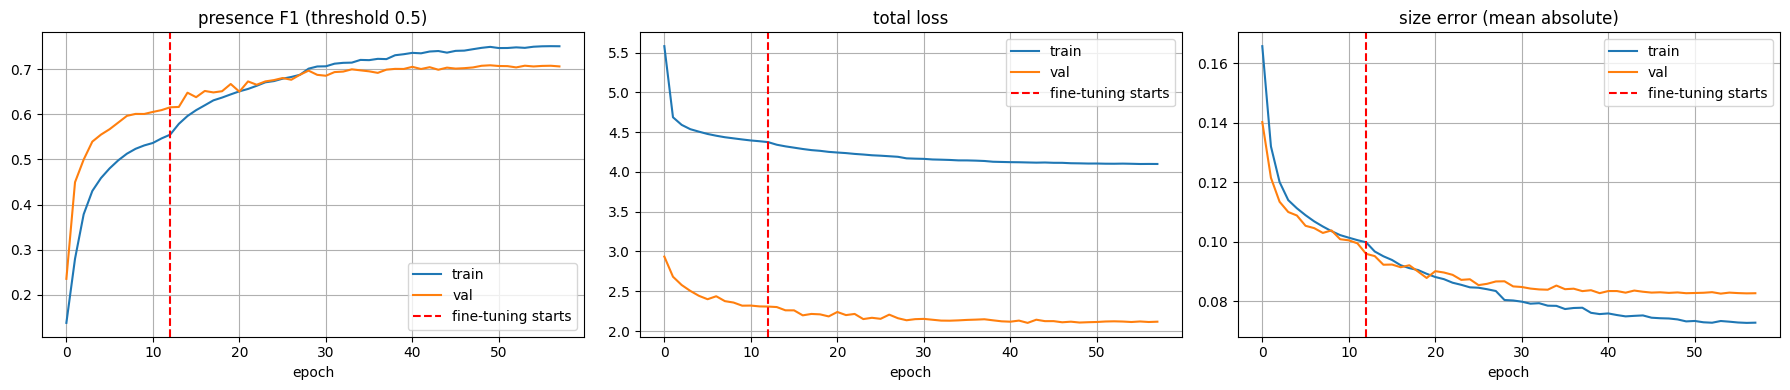

In [12]:
# CELL 8 - TRAINING PHASE 2: unfreeze the whole network and fine-tune with a very small learning rate; then plot the curves and save the float model.
for layer in model.layers:   # every layer
    layer.trainable = True   # unfreeze
for layer in model.layers:   # then
    if layer.name in BACKBONE_BN:   # keep the backbone's batch-norm layers frozen
        layer.trainable = False   # (steadier fine-tuning and better int8 behaviour)
compile_model(model, LR_FINE)   # re-compile so the change takes effect
class EMAWeights(keras.callbacks.Callback):   # keeps a running average of all weights while training (smoother than any single epoch)
    def __init__(self, decay):   # remember the decay
        super().__init__()   # base class
        self.decay = decay   # how slowly the average moves
    def on_train_begin(self, logs=None):   # when fine-tuning starts
        self.shadow = [tf.Variable(v, trainable=False) for v in self.model.weights]   # one average per weight, starting at the current value
        @tf.function   # compiled, so it costs almost no time per step
        def update():   # move every average a little towards the current weight
            for s_, v_ in zip(self.shadow, self.model.weights):   # every weight
                s_.assign(self.decay * s_ + (1.0 - self.decay) * v_)   # exponential moving average
        self.update = update   # keep the function
    def on_train_batch_end(self, batch, logs=None):   # after every training step
        self.update()   # update the averages

ema = EMAWeights(EMA_DECAY) if EMA_DECAY > 0 else None   # the averaging callback (or nothing)
t0 = time.time()   # start the clock
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, callbacks=callbacks_for(f'{OUT}/best.weights.h5', FINE_LR_PATIENCE, FINE_STOP_PATIENCE) + ([ema] if ema else []), verbose=2)   # fine-tune (the patience values and the averaging come from cell 0)
model.load_weights(f'{OUT}/best.weights.h5')   # go back to the best epoch
r2 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
if ema is not None:   # averaging was on
    raw_w = model.get_weights()   # keep the best single-epoch weights
    model.set_weights([s_.numpy() for s_ in ema.shadow])   # try the averaged weights
    r_ema = model.evaluate(val_ds, verbose=0, return_dict=True)   # their validation scores
    print(f"best single epoch: val F1 {r2['cls_f1']:.4f}, val loss {r2['loss']:.4f} | averaged weights: val F1 {r_ema['cls_f1']:.4f}, val loss {r_ema['loss']:.4f}")   # compare
    if r_ema['cls_f1'] >= r2['cls_f1']:   # the average is at least as good
        r2 = r_ema   # keep it
        print('-> using the averaged weights')   # say so
    else:   # the single epoch is better
        model.set_weights(raw_w)   # go back to it
        print('-> keeping the best single epoch')   # say so
print(f"phase 2 done in {(time.time() - t0) / 60:.1f} min | val F1 {r2['cls_f1']:.4f} | val size error {r2['size_mae']:.4f}")   # result
model.save(f'{OUT}/float_model.keras')   # save the full float model
model.save_weights(f'{OUT}/float.weights.h5')   # and just its weights

h1, h2 = hist1.history, hist2.history   # the two training logs
cut = len(h1['loss'])   # epoch where fine-tuning starts
fig, ax = plt.subplots(1, 3, figsize=(18, 4))   # three charts
ax[0].plot(h1['cls_f1'] + h2['cls_f1'], label='train'); ax[0].plot(h1['val_cls_f1'] + h2['val_cls_f1'], label='val')   # presence F1
ax[0].set_title('presence F1 (threshold 0.5)')   # chart title
ax[1].plot(h1['loss'] + h2['loss'], label='train'); ax[1].plot(h1['val_loss'] + h2['val_loss'], label='val')   # total loss
ax[1].set_title('total loss')   # chart title
ax[2].plot(h1['size_mae'] + h2['size_mae'], label='train'); ax[2].plot(h1['val_size_mae'] + h2['val_size_mae'], label='val')   # size error
ax[2].set_title('size error (mean absolute)')   # chart title
for a in ax:   # decorate all three
    a.axvline(cut, color='red', linestyle='--', label='fine-tuning starts'); a.set_xlabel('epoch'); a.grid(True); a.legend()   # phase marker, label, grid, legend
plt.tight_layout(); plt.savefig(f'{OUT}/training_curves.png', dpi=130); plt.show()   # save and show

## Part D - Evaluation of the float model
Mean average precision, precision / recall / F1, the share of danger objects found, size and distance-band errors for every present object, and the old-style top-1 accuracy. These tools are reused for every compressed candidate.

In [13]:
# CELL 9 - EVALUATION TOOLS + FLOAT MODEL RESULTS: detection quality (mean average precision, precision / recall / F1), size and distance-band errors for every present object, and the old-style top-1 accuracy for comparison with the earlier single-label models.
def predict_float(m, split):   # run a Keras model over one split
    out = m.predict(make_ds(split, False), verbose=0)   # [presence logits (N x 27), sizes (N x 27 x 1)]
    return out[0], out[1][:, :, 0]   # logits (N x 27) and sizes (N x 27)

def average_precision(score, y, w):   # average precision of one class over the known pictures (1.0 = perfect ranking)
    m = w > 0   # only pictures where this class is labelled
    s, t = score[m], y[m]   # their scores and truths
    if t.sum() == 0:   # the class never occurs
        return float('nan')   # no value
    t = t[np.argsort(-s)]   # truths in order of decreasing score
    prec = np.cumsum(t) / np.arange(1, len(t) + 1)   # precision after each picture
    return float((prec * t).sum() / t.sum())   # average of the precision at every true object

def prf(prob, y, w, thr):   # precision, recall, F1 and false alarms per picture at one threshold (known entries only)
    pred = prob >= thr   # classes called present
    tp = float(((pred) & (y > 0) & (w > 0)).sum()); fp = float(((pred) & (y == 0) & (w > 0)).sum()); fn = float(((~pred) & (y > 0) & (w > 0)).sum())   # counts
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)   # precision and recall
    return p, r, 2 * tp / max(2 * tp + fp + fn, 1), fp / len(y)   # F1 and false alarms per picture

def evaluate_predictions(name, logits, sizes, split, verbose=True):   # all metrics for one model on one split
    M = MULTI[split]; y, w, sz_true = M['pres'], M['known'], M['size']   # multi-label ground truth
    prob = sigmoid(logits / CAL['temp'])   # presence probabilities
    aps = np.array([average_precision(prob[:, c], y[:, c], w[:, c]) for c in range(NC)])   # AP per class
    mAP = float(np.nanmean(aps))   # mean over the classes that occur
    p_, r_, f1_, fa_ = prf(prob, y, w, thr_vec())   # precision / recall / F1 at the current thresholds
    top1 = float((logits.argmax(1) == INDEX[split][1]).mean())   # old-style: is the strongest score the main class?
    rows, cols = np.where(y > 0)   # every present object (picture, class)
    ts, ps = sz_true[rows, cols], sizes[rows, cols]   # its true and predicted size
    size_mae = float(np.abs(ps - ts).mean())   # mean absolute size error over present objects
    tb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cols, ts)])   # true distance band (from the annotated box)
    pb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cols, ps)])   # predicted distance band (true class, predicted size)
    band_acc, within1 = float((tb == pb).mean()), float((np.abs(tb - pb) <= 1).mean())   # exact band and off-by-at-most-one
    near_true = tb <= 1   # truly closer than 2 m
    missed = float(((pb >= 2) & near_true).sum() / max(near_true.sum(), 1))   # share of those reported as 2 m or farther (dangerous mistakes)
    hz = np.array([CLASS_INFO[c][2] for c in CLASS_LIST])   # hazard level of every class
    danger = (hz[None, :] == 2) & (y > 0) & (w > 0)   # real danger objects
    d_rec = float(((prob >= thr_vec()) & danger).sum() / max(danger.sum(), 1))   # share of them that are found
    res = dict(name=name, split=split, map=mAP, precision=p_, recall=r_, f1=f1_, false_per_pic=fa_, top1=top1, size_mae=size_mae, band_acc=band_acc, within1=within1, missed_near=missed, danger_recall=d_rec, aps=aps)   # the summary
    if verbose:   # print the details
        print(f'--- {name} on {split} ---')   # title
        print(f'mean average precision {mAP:.4f} | at the current thresholds: precision {p_:.3f} recall {r_:.3f} F1 {f1_:.3f} | false alarms per picture {fa_:.2f} | danger objects found {d_rec:.3f}')   # detection quality
        print(f'old-style top-1 accuracy {top1:.4f} (is the strongest score the main object?)')   # comparison with v3 / v4 / v5
        print(f'size error {size_mae:.4f} | band exact {band_acc:.3f} | band within 1 {within1:.3f} | near objects reported as far {missed:.3f}   (all present objects)')   # distance quality
        print('average precision per class:', '  '.join(f'{CLASS_LIST[c]}={aps[c]:.2f}' for c in np.argsort(np.nan_to_num(aps, nan=9)) if not np.isnan(aps[c])))   # worst classes first
        cm = np.zeros((4, 4), int)   # band confusion matrix
        for a, b in zip(tb, pb):   # every present object
            cm[a, b] += 1   # count (true band, predicted band)
        print('band confusion (rows = true, columns = predicted: very close / close / near / far):')   # explanation
        print(cm)   # the matrix
    return res   # the summary

lg, sz = predict_float(model, 'val')   # float model on the validation split
float_val = evaluate_predictions('float Keras model', lg, sz, 'val')   # evaluate and print


--- float Keras model on val ---
mean average precision 0.7905 | at the current thresholds: precision 0.730 recall 0.689 F1 0.709 | false alarms per picture 0.38 | danger objects found 0.687
old-style top-1 accuracy 0.6500 (is the strongest score the main object?)
size error 0.0827 | band exact 0.686 | band within 1 0.974 | near objects reported as far 0.125   (all present objects)
average precision per class: object=0.52  car=0.58  couch=0.59  bench=0.63  dog=0.63  truck=0.64  chair=0.65  table=0.68  bed=0.69  cat=0.74  bird=0.78  tv=0.79  bicycle=0.79  person=0.80  animal=0.81  bus=0.82  motorcycle=0.83  traffic light=0.86  fire hydrant=0.87  sink=0.87  toilet=0.88  stop sign=0.96  stairs=0.97  vegetation=0.99  crosswalk=0.99  door=0.99  pothole=1.00
band confusion (rows = true, columns = predicted: very close / close / near / far):
[[630 165  22   0]
 [121 956 241   4]
 [ 23 308 834  76]
 [  1  55 247 345]]


## Part E - Compression: quantization first, pruning only if needed

### Int8 quantization (main step)
Full-integer post-training quantization with 297 calibration images. The `.tflite` takes an int8 image and returns int8 results, as a microcontroller expects.

In [14]:
# CELL 10 - INT8 QUANTIZATION (the main compression step): post-training full-integer conversion using ~300 calibration images.
def load_np(path):   # one image file -> float32 array scaled -1..1, exactly as in training (RGB, not BGR)
    x = tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=3)   # read and decode as RGB
    if SRC_SIZE != IMG_SIZE:   # only when the model input differs from the stored size
        x = tf.cast(tf.image.resize(x, [IMG_SIZE, IMG_SIZE], antialias=True), tf.uint8)   # resize the square picture
    return x.numpy().astype(np.float32) / 255.0 * 2.0 - 1.0   # scale to -1..1

rng = random.Random(SEED)   # repeatable random choice
tr_paths, tr_labels, _ = INDEX['train']   # training index
calib_paths = []   # calibration images, the same number from every class
for c in range(NC):   # every class
    ids = list(np.where(tr_labels == c)[0])   # its training images
    calib_paths += [tr_paths[i] for i in rng.sample(ids, min(CALIB_PER_CLASS, len(ids)))]   # random few of them
print('calibration images:', len(calib_paths))   # how many

def representative_dataset():   # the converter calls this to learn the value range of every layer
    for p in calib_paths:   # each calibration image
        yield [load_np(p)[None]]   # one batch of one image

def to_int8_tflite(m, representative=True):   # Keras model -> fully-integer TFLite bytes
    conv = tf.lite.TFLiteConverter.from_keras_model(m)   # converter for this model
    conv.optimizations = [tf.lite.Optimize.DEFAULT]   # enable quantization
    if representative:   # post-training quantization needs example data
        conv.representative_dataset = representative_dataset   # give it the calibration images
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]   # allow integer operations only
    conv.inference_input_type = tf.int8   # the camera image goes in as int8
    conv.inference_output_type = tf.int8   # results come out as int8
    return conv.convert()   # run the conversion

def gzip_size(b):   # compressed size in bytes (the MNIST notebook reports this too)
    return len(zlib.compress(b, 9))   # deflate at the highest level

def float_share(b):   # share of tensor memory that is still floating point (about 0 for a fully-integer model)
    ip = tf.lite.Interpreter(model_content=b)   # open the model
    ip.allocate_tensors()   # prepare its tensors
    tot = flt = 0   # all bytes / float bytes
    for t in ip.get_tensor_details():   # every tensor in the model
        n = int(np.prod(t['shape'])) * np.dtype(t['dtype']).itemsize   # its size in bytes
        tot += n   # add to the total
        flt += n if t['dtype'] == np.float32 else 0   # add to the float total when it is float32
    return flt / max(tot, 1)   # fraction that is float

def arena_kb(b):   # estimated peak memory for the intermediate tensors (the 'tensor arena' a microcontroller needs in RAM), in KB
    ip = tf.lite.Interpreter(model_content=b); ip.allocate_tensors()   # open the model
    det = {t['index']: t for t in ip.get_tensor_details()}   # every tensor
    ops = ip._get_ops_details()   # the operations in execution order
    nbytes = lambda i: int(np.prod(det[i]['shape'])) * np.dtype(det[i]['dtype']).itemsize   # size of one tensor in bytes
    first, last = {}, {}   # first and last operation that touches each tensor
    for k, o in enumerate(ops):   # every operation
        for i in list(o['inputs']) + list(o['outputs']):   # every tensor it reads or writes
            if i >= 0:   # valid tensor
                first.setdefault(i, k); last[i] = k   # remember when it is needed
    act = {i for o in ops for i in o['outputs']} | {t['index'] for t in ip.get_input_details()}   # activations (not the constant weights)
    return max(sum(nbytes(i) for i in act if i in first and first[i] <= k <= last[i]) for k in range(len(ops))) / 1e3   # the busiest moment (a rough estimate; the real TFLite-Micro arena adds a little overhead)

SIZES = {}   # name -> (raw bytes, compressed bytes)
float_tflite = tf.lite.TFLiteConverter.from_keras_model(model).convert()   # un-quantized TFLite, only for the size comparison
SIZES['float32 TFLite'] = (len(float_tflite), gzip_size(float_tflite))   # remember its sizes
try:   # full-integer conversion can fail on unsupported layers
    ptq_bytes = to_int8_tflite(model)   # the int8 model
    print('full-integer quantization worked')   # success message
except Exception as e:   # fall back to the weaker dynamic-range quantization
    print('full-integer failed:', str(e)[:200], '\nfalling back to dynamic-range quantization')   # explain
    conv = tf.lite.TFLiteConverter.from_keras_model(model)   # new converter
    conv.optimizations = [tf.lite.Optimize.DEFAULT]   # weights int8, activations float
    ptq_bytes = conv.convert()   # convert
SIZES['int8 PTQ'] = (len(ptq_bytes), gzip_size(ptq_bytes))   # remember its sizes
open(f'{OUT}/model_int8_ptq.tflite', 'wb').write(ptq_bytes)   # save the file
for k, (raw, gz) in SIZES.items():   # print the size table
    print(f'{k:16s} {raw / 1e6:6.2f} MB raw | {gz / 1e6:6.2f} MB compressed')   # sizes


calibration images: 297


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


full-integer quantization worked
float32 TFLite     2.40 MB raw |   2.20 MB compressed
int8 PTQ           0.88 MB raw |   0.65 MB compressed


In [15]:
# CELL 11 - EVALUATE THE TFLITE MODEL: run the real int8 file image by image (as the device would) and compare with the float model.
def dequant(arr, d):   # integer tensor -> real numbers using the tensor's scale and zero point
    scale, zp = d['quantization']   # quantization parameters
    return arr.astype(np.float32) if scale == 0 else (arr.astype(np.float32) - zp) * scale   # real = (q - zero_point) * scale

def run_tflite(tfl, paths):   # list of image files -> (presence logits N x 27, sizes N x 27) from a TFLite model
    it = tf.lite.Interpreter(model_content=tfl, num_threads=2)   # the TFLite interpreter
    it.allocate_tensors()   # prepare its memory
    inp = it.get_input_details()[0]   # the input tensor
    outs = it.get_output_details()   # the output tensors
    cls_d = next(o for o in outs if o['shape'][-1] == NC)   # the output that ends in 27 is the presence scores
    size_d = next(o for o in outs if o['shape'][-1] == 1)   # the output that ends in 1 (27 x 1) is the sizes
    scale, zp = inp['quantization']   # how to turn real input values into integers
    L, S = [], []   # collected logits and sizes
    for i, p in enumerate(paths):   # every image
        x = load_np(p)[None]   # float input -1..1
        if inp['dtype'] != np.float32:   # integer model
            info = np.iinfo(inp['dtype'])   # allowed integer range
            x = np.clip(np.round(x / scale + zp), info.min, info.max).astype(inp['dtype'])   # quantize the input
        it.set_tensor(inp['index'], x)   # feed the image
        it.invoke()   # run the network
        L.append(dequant(it.get_tensor(cls_d['index'])[0], cls_d))   # presence scores as real numbers
        S.append(dequant(it.get_tensor(size_d['index'])[0], size_d)[:, 0])   # the 27 sizes as real numbers
        if (i + 1) % 1000 == 0:   # progress
            print(f'  {i + 1}/{len(paths)} images')   # show it
    return np.array(L), np.array(S)   # arrays

def eval_tflite(name, tfl, split, verbose=True):   # evaluate a TFLite model on a whole split
    lg_, sz_ = run_tflite(tfl, INDEX[split][0])   # run it
    return evaluate_predictions(name, lg_, sz_, split, verbose)   # metrics

CANDIDATES = {}   # name -> {'bytes': model file, 'val': validation metrics}
t0 = time.time()   # start the clock
ptq_val = eval_tflite('int8 PTQ', ptq_bytes, 'val')   # evaluate the int8 model on validation data
CANDIDATES['int8 PTQ'] = dict(bytes=ptq_bytes, val=ptq_val)   # remember it
print(f'evaluation took {time.time() - t0:.0f} s')   # how long

def show_table():   # side-by-side comparison of everything built so far
    print(f"{'model':22s}{'val mAP':>9s}{'val F1':>8s}{'size err':>10s}{'band acc':>10s}{'raw MB':>9s}{'zip MB':>9s}")   # header
    print(f"{'float Keras':22s}{float_val['map']:9.4f}{float_val['f1']:8.3f}{float_val['size_mae']:10.4f}{float_val['band_acc']:10.3f}{'-':>9s}{'-':>9s}")   # baseline row
    for k, v in CANDIDATES.items():   # each compressed candidate
        raw, gz = SIZES[k]   # its sizes
        print(f"{k:22s}{v['val']['map']:9.4f}{v['val']['f1']:8.3f}{v['val']['size_mae']:10.4f}{v['val']['band_acc']:10.3f}{raw / 1e6:9.2f}{gz / 1e6:9.2f}")   # one row each
show_table()   # print it


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


  1000/2700 images
  2000/2700 images
--- int8 PTQ on val ---
mean average precision 0.7854 | at the current thresholds: precision 0.717 recall 0.688 F1 0.702 | false alarms per picture 0.40 | danger objects found 0.678
old-style top-1 accuracy 0.6411 (is the strongest score the main object?)
size error 0.0833 | band exact 0.681 | band within 1 0.975 | near objects reported as far 0.127   (all present objects)
average precision per class: object=0.52  car=0.57  couch=0.58  bench=0.62  dog=0.62  truck=0.62  chair=0.65  bed=0.67  table=0.68  cat=0.73  bird=0.77  tv=0.79  person=0.80  bicycle=0.80  animal=0.80  bus=0.81  traffic light=0.84  motorcycle=0.84  fire hydrant=0.85  sink=0.87  toilet=0.87  stop sign=0.96  stairs=0.96  vegetation=0.99  crosswalk=0.99  door=0.99  pothole=1.00
band confusion (rows = true, columns = predicted: very close / close / near / far):
[[620 174  23   0]
 [117 957 242   6]
 [ 21 302 835  83]
 [  1  50 266 331]]
evaluation took 28 s
model                   va

### Pruning (only if the int8 file is bigger than `TARGET_MB`)
Pruning is switched off in this variant (the model is already small); the cell reports that and moves on.

In [16]:
# CELL 12 - PRUNING (only if needed): zeroes the smallest weights of the two big fully connected layers, fine-tunes, then re-quantizes.
# Note: pruning mainly shrinks the COMPRESSED file; the raw .tflite that sits in the device's flash keeps the same size.
size_mb = len(ptq_bytes) / 1e6   # size of the plain int8 file
need_prune = RUN_PRUNING is True or (RUN_PRUNING == 'auto' and size_mb > TARGET_MB)   # run when asked, or when the file is too big
print(f'int8 file {size_mb:.2f} MB (wanted <= {TARGET_MB} MB) -> pruning {"RUNS" if need_prune else "is skipped"}')   # decision
if need_prune:   # only then
    is_pruned = lambda l: type(l).__name__ == 'PruneLowMagnitude'   # True for the wrapper layer that holds a pruned layer
    steps = math.ceil(len(INDEX['train'][0]) / BATCH) * EPOCHS_PRUNE   # total training steps during pruning
    schedule = tfmot.sparsity.keras.PolynomialDecay(initial_sparsity=0.10, final_sparsity=PRUNE_FINAL_SPARSITY, begin_step=0, end_step=steps, frequency=max(1, min(100, steps // 20)))   # sparsity grows from 10 percent to the target; the mask is refreshed regularly
    def wrap(layer):   # decide per layer whether to prune it
        fresh = layer.__class__.from_config(layer.get_config())   # an independent copy (the original float model stays untouched)
        if isinstance(layer, keras.layers.Dense) and layer.name in ('fc1', 'fc2'):   # only the two big fully connected layers
            return tfmot.sparsity.keras.prune_low_magnitude(fresh, pruning_schedule=schedule)   # wrap it for pruning
        return fresh   # every other layer is copied as it is
    pm = keras.models.clone_model(model, clone_function=wrap)   # copy of the model with pruning wrappers
    for layer in pm.layers:   # copy the trained weights across, layer by layer
        inner = layer.layer if is_pruned(layer) else layer   # the real layer inside a wrapper
        inner.set_weights(model.get_layer(inner.name).get_weights())   # same name in the original model
    for layer in pm.layers:   # only the pruned layers keep training
        layer.trainable = is_pruned(layer)   # everything else is frozen
    compile_model(pm, 2e-5)   # same losses and metrics as the main model, small learning rate
    pm.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PRUNE, callbacks=[tfmot.sparsity.keras.UpdatePruningStep()], verbose=2)   # fine-tune while the mask grows
    stripped = tfmot.sparsity.keras.strip_pruning(pm)   # remove the pruning wrappers, keep the zeros
    for n in ('fc1', 'fc2'):   # report what was achieved
        w = stripped.get_layer(n).get_weights()[0]   # that layer's weights
        print(f'{n}: {float((w == 0).mean()) * 100:.1f} percent of weights are zero')   # sparsity
    pr_bytes = to_int8_tflite(stripped)   # quantize the pruned model
    SIZES['int8 PTQ + pruned'] = (len(pr_bytes), gzip_size(pr_bytes))   # remember its sizes
    open(f'{OUT}/model_int8_pruned.tflite', 'wb').write(pr_bytes)   # save the file
    CANDIDATES['int8 PTQ + pruned'] = dict(bytes=pr_bytes, val=eval_tflite('int8 PTQ + pruned', pr_bytes, 'val', verbose=False))   # evaluate and remember
    show_table()   # updated comparison


int8 file 0.88 MB (wanted <= 0.9 MB) -> pruning is skipped


### Choose the final model
Only candidates that keep the detection score (mAP) and the size accuracy within the limits and are fully integer can be chosen. The test split is used once, here.

In [17]:
# CELL 13 - CHOOSE THE FINAL MODEL and measure it ONCE on the untouched test split.
FORCE_CHOICE = None   # type a candidate name (for example 'int8 PTQ') to override the automatic choice
ok = {k: v for k, v in CANDIDATES.items() if float_val['map'] - v['val']['map'] <= MAX_ACC_DROP and v['val']['size_mae'] - float_val['size_mae'] <= MAX_SIZE_RISE and float_share(v['bytes']) < 0.02}   # candidates that keep BOTH the detection score (mAP) and the size (distance) accuracy AND are fully integer
for k, v in CANDIDATES.items():   # explain every candidate
    print(f"  {k:20s} mAP change {(v['val']['map'] - float_val['map']) * 100:+.2f} points | size error change {v['val']['size_mae'] - float_val['size_mae']:+.4f} | float tensors {float_share(v['bytes']) * 100:.1f} percent | {'accepted' if k in ok else 'REJECTED'}")   # verdict per candidate
pool = ok if ok else CANDIDATES   # if none qualifies, choose among all
if not ok:   # nothing met the limits
    print('WARNING: no candidate met the limits, so the most accurate one is used. Try a larger CALIB_PER_CLASS, or look at the per-class results above.')   # tell the user
best = FORCE_CHOICE or max(pool, key=lambda k: (round(pool[k]['val']['map'], 3), -SIZES[k][0]))   # highest val mAP, then the smallest file
print('candidates within the accuracy limit:', list(ok) or 'none', '| chosen:', best)   # explain the choice
final_bytes = CANDIDATES[best]['bytes']   # the chosen model file
FINAL_TFLITE = f'{OUT}/irp_navigation_v6.tflite'   # where it is saved
open(FINAL_TFLITE, 'wb').write(final_bytes)   # write it
it = tf.lite.Interpreter(model_content=final_bytes); it.allocate_tensors()   # open it to read its tensor details
IN = it.get_input_details()[0]   # input tensor details
IN_SCALE, IN_ZP = IN['quantization']   # how real input values map to integers
print(f"final model: {len(final_bytes) / 1e6:.2f} MB | input {IN['dtype'].__name__} {tuple(IN['shape'])}, scale {IN_SCALE:.6f}, zero point {IN_ZP}")   # facts the firmware needs
lg_f, sz_f = predict_float(model, 'test')   # float model on the test split
float_test = evaluate_predictions('float Keras model', lg_f, sz_f, 'test', verbose=False)   # its test metrics
final_test = eval_tflite(f'FINAL {best}', final_bytes, 'test')   # the final model on the test split (printed in full)
print(f"\nTEST mean average precision: float {float_test['map']:.4f} -> final int8 {final_test['map']:.4f} (change {(final_test['map'] - float_test['map']) * 100:+.2f} points) | F1 {float_test['f1']:.3f} -> {final_test['f1']:.3f}")   # headline comparison


  int8 PTQ             mAP change -0.52 points | size error change +0.0006 | float tensors 0.0 percent | accepted
candidates within the accuracy limit: ['int8 PTQ'] | chosen: int8 PTQ
final model: 0.88 MB | input int8 (np.int32(1), np.int32(144), np.int32(144), np.int32(3)), scale 0.007843, zero point -1
  1000/2700 images
  2000/2700 images
--- FINAL int8 PTQ on test ---
mean average precision 0.7859 | at the current thresholds: precision 0.714 recall 0.687 F1 0.700 | false alarms per picture 0.41 | danger objects found 0.702
old-style top-1 accuracy 0.6444 (is the strongest score the main object?)
size error 0.0835 | band exact 0.672 | band within 1 0.974 | near objects reported as far 0.138   (all present objects)
average precision per class: object=0.56  chair=0.56  couch=0.59  dog=0.60  bench=0.61  car=0.62  bed=0.66  table=0.68  truck=0.69  bird=0.73  tv=0.77  cat=0.77  bicycle=0.77  person=0.78  sink=0.80  animal=0.82  traffic light=0.87  fire hydrant=0.87  bus=0.88  motorcycle=

### Calibration (no retraining)
Fitted on the validation split and checked on the test split: (1) a **temperature** for the presence scores, (2) the **detection threshold** (the best F1, but never so high that fewer than `DANGER_RECALL_TARGET` of the real danger objects are found), (3) whether a straight-line **size correction** is worth using, (4) a **safety margin** that leans distances towards 'closer' until at most `MISSED_NEAR_TARGET` of the truly near objects are reported as far. Section 5 reports the final test numbers.

In [18]:
# CELL 13b - CALIBRATION (no retraining): fitted on the VALIDATION split, checked on the TEST split. Fits (1) a temperature for the presence scores, (2) the detection threshold, (3) the size correction and a safety margin towards "closer".
lg_v, sz_v = run_tflite(final_bytes, INDEX['val'][0])   # final int8 model on the validation split (used to FIT the corrections)
lg_t, sz_t = run_tflite(final_bytes, INDEX['test'][0])   # and on the test split (used only to CHECK them)
Mv, Mt = MULTI['val'], MULTI['test']   # multi-label truths of both splits
haz = np.array([CLASS_INFO[n][2] for n in CLASS_LIST])   # hazard level of each class

def masked_nll(lg_, M, temp):   # average binary negative log-likelihood over the known entries (lower = better calibrated)
    p = np.clip(sigmoid(lg_ / temp), 1e-6, 1 - 1e-6)   # probabilities, kept away from 0 and 1
    ll = M['pres'] * np.log(p) + (1 - M['pres']) * np.log(1 - p)   # log-likelihood of every entry
    return float(-(M['known'] * ll).sum() / M['known'].sum())   # mean over the known entries

temps = np.arange(0.2, 5.001, 0.05)   # candidate temperatures
T = float(temps[int(np.argmin([masked_nll(lg_v, Mv, t) for t in temps]))])   # the one that fits the validation data best
print(f'1) temperature of the presence scores T = {T:.2f}  (T > 1 means the model was over-confident)')   # result
print(f'   test: loss {masked_nll(lg_t, Mt, 1.0):.4f} -> {masked_nll(lg_t, Mt, T):.4f}')   # before -> after
CAL['temp'] = T   # from now on the probabilities use this temperature
prob_v, prob_t = sigmoid(lg_v / T), sigmoid(lg_t / T)   # calibrated probabilities

def danger_recall(prob, M, thr):   # share of the real danger objects (hazard level 2) that are found at a threshold
    d = (haz[None, :] == 2) & (M['pres'] > 0) & (M['known'] > 0)   # danger entries
    return float(((prob >= thr) & d).sum() / max(d.sum(), 1))   # found / all

print('\n2) detection threshold (a class counts as present when its probability reaches it)')   # explanation
print(f"   {'thr':>5s} | {'val prec':>8s} {'val rec':>8s} {'val F1':>7s} {'val danger':>10s} | {'test prec':>9s} {'test rec':>8s} {'test F1':>7s} {'test danger':>11s} {'false/pic':>9s}")   # header
grid = np.round(np.arange(0.10, 0.901, 0.05), 2)   # candidate thresholds
f1_v = [prf(prob_v, Mv['pres'], Mv['known'], g)[2] for g in grid]   # validation F1 of each
thr_f1 = float(grid[int(np.argmax(f1_v))])   # the threshold with the best F1
ok_d = [g for g in grid if danger_recall(prob_v, Mv, g) >= DANGER_RECALL_TARGET]   # thresholds that still find enough dangers
thr_danger = float(max(ok_d)) if ok_d else float(grid[0])   # the strictest of them (the lowest threshold if none qualifies)
THR = min(thr_f1, thr_danger)   # use the lower of the two: never miss many dangers just to gain precision
show = {round(float(x), 2) for x in np.arange(0.1, 0.91, 0.1)} | {round(thr_f1, 2), round(thr_danger, 2), round(THR, 2)}   # every 0.10 plus the interesting thresholds
for g in grid:   # print the selected candidates
    if round(float(g), 2) in show:   # only those
        pv, rv, fv, _ = prf(prob_v, Mv['pres'], Mv['known'], g)   # validation numbers
        pt, rt, ft, fa = prf(prob_t, Mt['pres'], Mt['known'], g)   # test numbers (for checking only)
        print(f"   {g:5.2f} | {pv:8.3f} {rv:8.3f} {fv:7.3f} {danger_recall(prob_v, Mv, g):10.3f} | {pt:9.3f} {rt:8.3f} {ft:7.3f} {danger_recall(prob_t, Mt, g):11.3f} {fa:9.2f}{'   <- chosen' if round(float(g), 2) == round(THR, 2) else ''}")   # one row
print(f'   best F1 at {thr_f1:.2f}; dangers found >= {DANGER_RECALL_TARGET:.0%} up to {thr_danger:.2f}; chosen threshold {THR:.2f}')   # explanation
CAL['thr'] = THR   # from now on decide_all() uses this threshold

print('\n2b) one threshold per class (a rare or hard class needs a different cut-off than an easy one)')   # explanation
beta = np.where(haz == 2, DANGER_BETA, 1.0)   # danger classes: recall counts DANGER_BETA times as much as precision; the others: plain F1
fit_thr = np.full(NC, THR)   # start with the global threshold for every class
for c in range(NC):   # fit every class on its own
    k = Mv['known'][:, c] > 0   # validation pictures where this class is labelled
    y_c, p_c = Mv['pres'][k, c] > 0, prob_v[k, c]   # their truths and probabilities
    if y_c.sum() < 10:   # too few examples to trust a threshold
        continue   # keep the global one
    best_f, best_g = -1.0, THR   # best score so far
    for g in grid:   # every candidate threshold
        tp, fp, fn = float((p_c >= g)[y_c].sum()), float((p_c >= g)[~y_c].sum()), float((p_c < g)[y_c].sum())   # counts at this threshold
        f = (1 + beta[c] ** 2) * tp / max((1 + beta[c] ** 2) * tp + beta[c] ** 2 * fn + fp, 1e-9)   # F-beta score
        if f > best_f + 1e-9:   # strictly better (ties keep the lower threshold = the safer one)
            best_f, best_g = f, float(g)   # remember
    fit_thr[c] = best_g   # the best threshold of this class
thr_c = (1 - THR_SHRINK) * fit_thr + THR_SHRINK * THR   # pull towards the global threshold (less noise)
while danger_recall(prob_v, Mv, thr_c) < DANGER_RECALL_TARGET and (thr_c[haz == 2] > 0.06).any():   # the danger target must still hold
    thr_c[haz == 2] = np.maximum(thr_c[haz == 2] - 0.02, 0.05)   # lower the danger thresholds a little
thr_c = np.round(thr_c, 3)   # tidy numbers for the device
print('   ' + '  '.join(f'{CLASS_LIST[c]}={thr_c[c]:.2f}' for c in range(NC)))   # the thresholds
print(f"   {'':16s} {'prec':>6s} {'recall':>7s} {'F1':>6s} {'danger':>7s} {'false/pic':>9s}")   # header
for nm, tv in (('global', THR), ('per class', thr_c)):   # compare both
    for sp, P_, M_ in (('val', prob_v, Mv), ('test', prob_t, Mt)):   # on both splits (only val was used to fit)
        pp, rr, ff, fa_ = prf(P_, M_['pres'], M_['known'], tv)   # numbers
        print(f"   {nm + ' ' + sp:16s} {pp:6.3f} {rr:7.3f} {ff:6.3f} {danger_recall(P_, M_, tv):7.3f} {fa_:9.2f}")   # one row
CAL['thr_c'] = [float(t) for t in thr_c]   # from now on decide_all() uses one threshold per class

rows_v, cols_v = np.where(Mv['pres'] > 0)   # every present object in validation (picture, class)
sp_v, st_v = sz_v[rows_v, cols_v], Mv['size'][rows_v, cols_v]   # its predicted and true size
rows_t, cols_t = np.where(Mt['pres'] > 0)   # and in test
sp_t, st_t = sz_t[rows_t, cols_t], Mt['size'][rows_t, cols_t]   # predicted and true size
a_lin, b_lin = (float(v) for v in np.polyfit(sp_v, st_v, 1))   # straight line fitted on validation: true size = a * predicted size + b
a, b = a_lin, b_lin   # start with the line (the choice between 'no correction' and 'line' is made below)
print(f'\n3) size correction candidates: line true = {a_lin:.3f} x predicted + {b_lin:+.3f}, or no correction')   # result
for name, fix in (('raw', lambda z: z), ('line', lambda z: np.clip(a_lin * z + b_lin, 0.02, 1.0))):   # before and after the line
    e = fix(sp_t) - st_t   # signed error on the test split
    bias = lambda m: float(e[m].mean()) if m.any() else float('nan')   # average signed error of a group (nan when empty)
    print(f'   test {name:5s}: MAE {np.abs(e).mean():.4f} | bias small objects (<0.2) {bias(st_t < 0.2):+.3f} | big objects (>0.6) {bias(st_t > 0.6):+.3f}')   # error and bias

def band_stats(size_pred, cls, size_true, margin, a_=None, b_=None):   # distance-band errors for a set of present objects after the correction and a margin
    a_, b_ = (a if a_ is None else a_), (b if b_ is None else b_)   # use the chosen correction unless one is given
    adj = np.clip((a_ * size_pred + b_) * (1.0 + margin), 0.02, 1.0)   # corrected size with the margin
    tb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cls, size_true)])   # true band (from the annotated box)
    pb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cls, adj)])   # predicted band
    missed = float(((pb >= 2) & (tb <= 1)).sum() / max((tb <= 1).sum(), 1))   # truly < 2 m but reported 2 m or farther (dangerous)
    false_alarm = float(((pb <= 1) & (tb >= 2)).sum() / max((tb >= 2).sum(), 1))   # truly 2 m or farther but reported < 2 m (annoying)
    return missed, false_alarm, float((tb == pb).mean())   # the three numbers

margins = np.round(np.arange(0.0, 0.501, 0.02), 2)   # candidate margins
def cheapest(a_, b_):   # smallest margin that reaches the missed-near target on validation -> (margin, false-alarm rate there)
    for mg in margins:   # from small to large
        mv, fv, _ = band_stats(sp_v, cols_v, st_v, mg, a_, b_)   # validation numbers
        if mv <= MISSED_NEAR_TARGET:   # target reached
            return float(mg), fv   # this margin and its price in false alarms
    return None, 1.0   # target not reachable
cost_none, cost_line = cheapest(1.0, 0.0), cheapest(a_lin, b_lin)   # both candidates
print(f"   to reach the target on validation: no correction -> margin {cost_none[0]}, false alarms {cost_none[1] * 100:.1f}% | line -> margin {cost_line[0]}, false alarms {cost_line[1] * 100:.1f}%")   # compare the price
if cost_line[0] is not None and cost_line[1] < cost_none[1] - 0.01:   # the line must save at least one point of false alarms to be worth it
    a, b = a_lin, b_lin   # use the line
    print('   -> using the line (it lowers the false alarms by more than 1 point)')   # decision
else:   # otherwise keep it simple
    a, b = 1.0, 0.0   # no size correction, only the safety margin
    print('   -> using NO size correction (the line does not help enough); only the safety margin is applied')   # decision

print(f'\n4) safety margin (size x (1 + margin)); target: at most {MISSED_NEAR_TARGET * 100:.0f} percent of near objects reported as far')   # explanation
print(f"   {'margin':>7s} | {'val missed':>10s} {'val false':>10s} | {'test missed':>11s} {'test false':>11s} {'test band acc':>13s}")   # header
chosen = None   # the margin we will use
for mg in margins:   # every candidate
    mv, fv, _ = band_stats(sp_v, cols_v, st_v, mg)   # validation numbers
    if chosen is None and mv <= MISSED_NEAR_TARGET:   # the smallest margin that reaches the target
        chosen = float(mg)   # take it
    if mg in (0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5) or mg == chosen:   # print a short table
        mt, ft, bt = band_stats(sp_t, cols_t, st_t, mg)   # test numbers (for checking only)
        print(f"   {mg:7.2f} | {mv * 100:9.1f}% {fv * 100:9.1f}% | {mt * 100:10.1f}% {ft * 100:10.1f}% {bt * 100:12.1f}%{'   <- chosen' if mg == chosen else ''}")   # one row
if chosen is None:   # the target cannot be reached with margins up to 0.5
    chosen = float(margins[int(np.argmin([band_stats(sp_v, cols_v, st_v, mg)[0] for mg in margins]))])   # take the margin with the fewest misses
    print('   WARNING: the target was not reached; using the margin with the fewest misses. The model itself needs to improve.')   # tell the user
CAL.update(temp=T, thr=THR, a=a, b=b, margin=chosen)   # (thr_c was set above)
#   # from now on decide_all() and the alert demo use these corrections
print(f'   -> CAL = {CAL}')   # what the device must apply

print('\n5) the final model on the TEST split with these settings:')   # explanation
pt, rt, ft, fa = prf(prob_t, Mt['pres'], Mt['known'], thr_c)   # precision, recall, F1, false alarms per picture (per-class thresholds)
aps_t = np.array([average_precision(prob_t[:, c], Mt['pres'][:, c], Mt['known'][:, c]) for c in range(NC)])   # AP per class
pred_set = prob_t >= thr_c   # classes called present
exact = float(np.mean([(pred_set[i][Mt['known'][i] > 0] == (Mt['pres'][i][Mt['known'][i] > 0] > 0)).all() for i in range(len(prob_t))]))   # pictures where every known class is right
top1 = float((lg_t.argmax(1) == INDEX['test'][1]).mean())   # old-style top-1 accuracy
main_found = float(np.mean(prob_t[np.arange(len(prob_t)), INDEX['test'][1]] >= thr_c[INDEX['test'][1]]))   # pictures whose main object is found
print(f'   mean average precision {np.nanmean(aps_t):.3f} | precision {pt:.3f} | recall {rt:.3f} | F1 {ft:.3f} | false alarms per picture {fa:.2f}')   # detection quality
print(f'   danger objects found {danger_recall(prob_t, Mt, thr_c):.3f} | main object found {main_found:.3f} | every class right in the picture {exact:.3f} | old-style top-1 {top1:.3f}')   # safety and comparison numbers
print('   weakest classes (average precision): ' + ', '.join(f'{CLASS_LIST[c]} {aps_t[c]:.2f}' for c in np.argsort(np.nan_to_num(aps_t, nan=9))[:8] if not np.isnan(aps_t[c])))   # where the model struggles
mt_, ft_, bt_ = band_stats(sp_t, cols_t, st_t, chosen)   # distance-band numbers on test with the chosen correction
final_cal = dict(map=float(np.nanmean(aps_t)), precision=pt, recall=rt, f1=ft, false_per_pic=fa, danger_recall=danger_recall(prob_t, Mt, thr_c), top1=top1, missed_near=mt_, band_acc=bt_)   # the numbers to report (test split, calibrated settings)
print(f'   distance bands with the correction: exact {bt_:.3f} | near objects reported as far {mt_ * 100:.1f}% | far objects reported as near {ft_ * 100:.1f}%')   # distance quality after calibration

print('\n6) honesty check: average precision inside ONE source dataset at a time (a model could otherwise score high just by recognising which dataset a picture came from)')   # explanation
src_t = SRCS['test']   # source of every test picture
rows_ = []   # (class, overall AP, worst single-source AP, that source, pictures)
for c in range(NC):   # every class
    worst = None   # worst single-source value
    for src in sorted(set(src_t)):   # every source
        k = (src_t == src) & (Mt['known'][:, c] > 0)   # its pictures where the class is labelled
        if (Mt['pres'][k, c] > 0).sum() >= 5 and (Mt['pres'][k, c] == 0).sum() >= 5:   # needs both examples and counter-examples
            ap_ = average_precision(prob_t[k, c], Mt['pres'][k, c], np.ones(int(k.sum())))   # AP inside this source only
            if worst is None or ap_ < worst[0]:   # lower than before
                worst = (ap_, src or '(unknown)', int(k.sum()))   # remember
    if worst is not None:   # the class could be tested inside a source
        rows_.append((c, aps_t[c], *worst))   # keep the row
for c, ap_all, ap_in, src, n in sorted(rows_, key=lambda r: r[2]):   # worst first
    print(f"   {CLASS_LIST[c]:14s} overall {ap_all:.2f} | inside '{src}' only {ap_in:.2f} ({n} pictures)" + ('   <- specialist class: the overall number is optimistic' if c in SPECIALIST and ap_all - ap_in > 0.05 else ''))   # one line per class


  1000/2700 images
  2000/2700 images
  1000/2700 images
  2000/2700 images
1) temperature of the presence scores T = 0.90  (T > 1 means the model was over-confident)
   test: loss 0.1317 -> 0.1304

2) detection threshold (a class counts as present when its probability reaches it)
     thr | val prec  val rec  val F1 val danger | test prec test rec test F1 test danger false/pic
    0.10 |    0.438    0.867   0.582      0.819 |     0.449    0.873   0.593       0.839      1.60   <- chosen
    0.20 |    0.539    0.806   0.646      0.760 |     0.549    0.809   0.654       0.786      0.99
    0.30 |    0.607    0.766   0.677      0.731 |     0.611    0.765   0.680       0.750      0.73
    0.40 |    0.669    0.721   0.694      0.703 |     0.670    0.723   0.695       0.721      0.53
    0.50 |    0.717    0.688   0.702      0.678 |     0.714    0.687   0.700       0.702      0.41
    0.60 |    0.769    0.640   0.698      0.646 |     0.764    0.637   0.695       0.676      0.29
    0.70 |   

## Part F - Alerts and speech
### Demo on test pictures
What the device would announce for 12 test pictures (mostly with several objects): every object it finds, the distance, the priority and the words of the most urgent one.

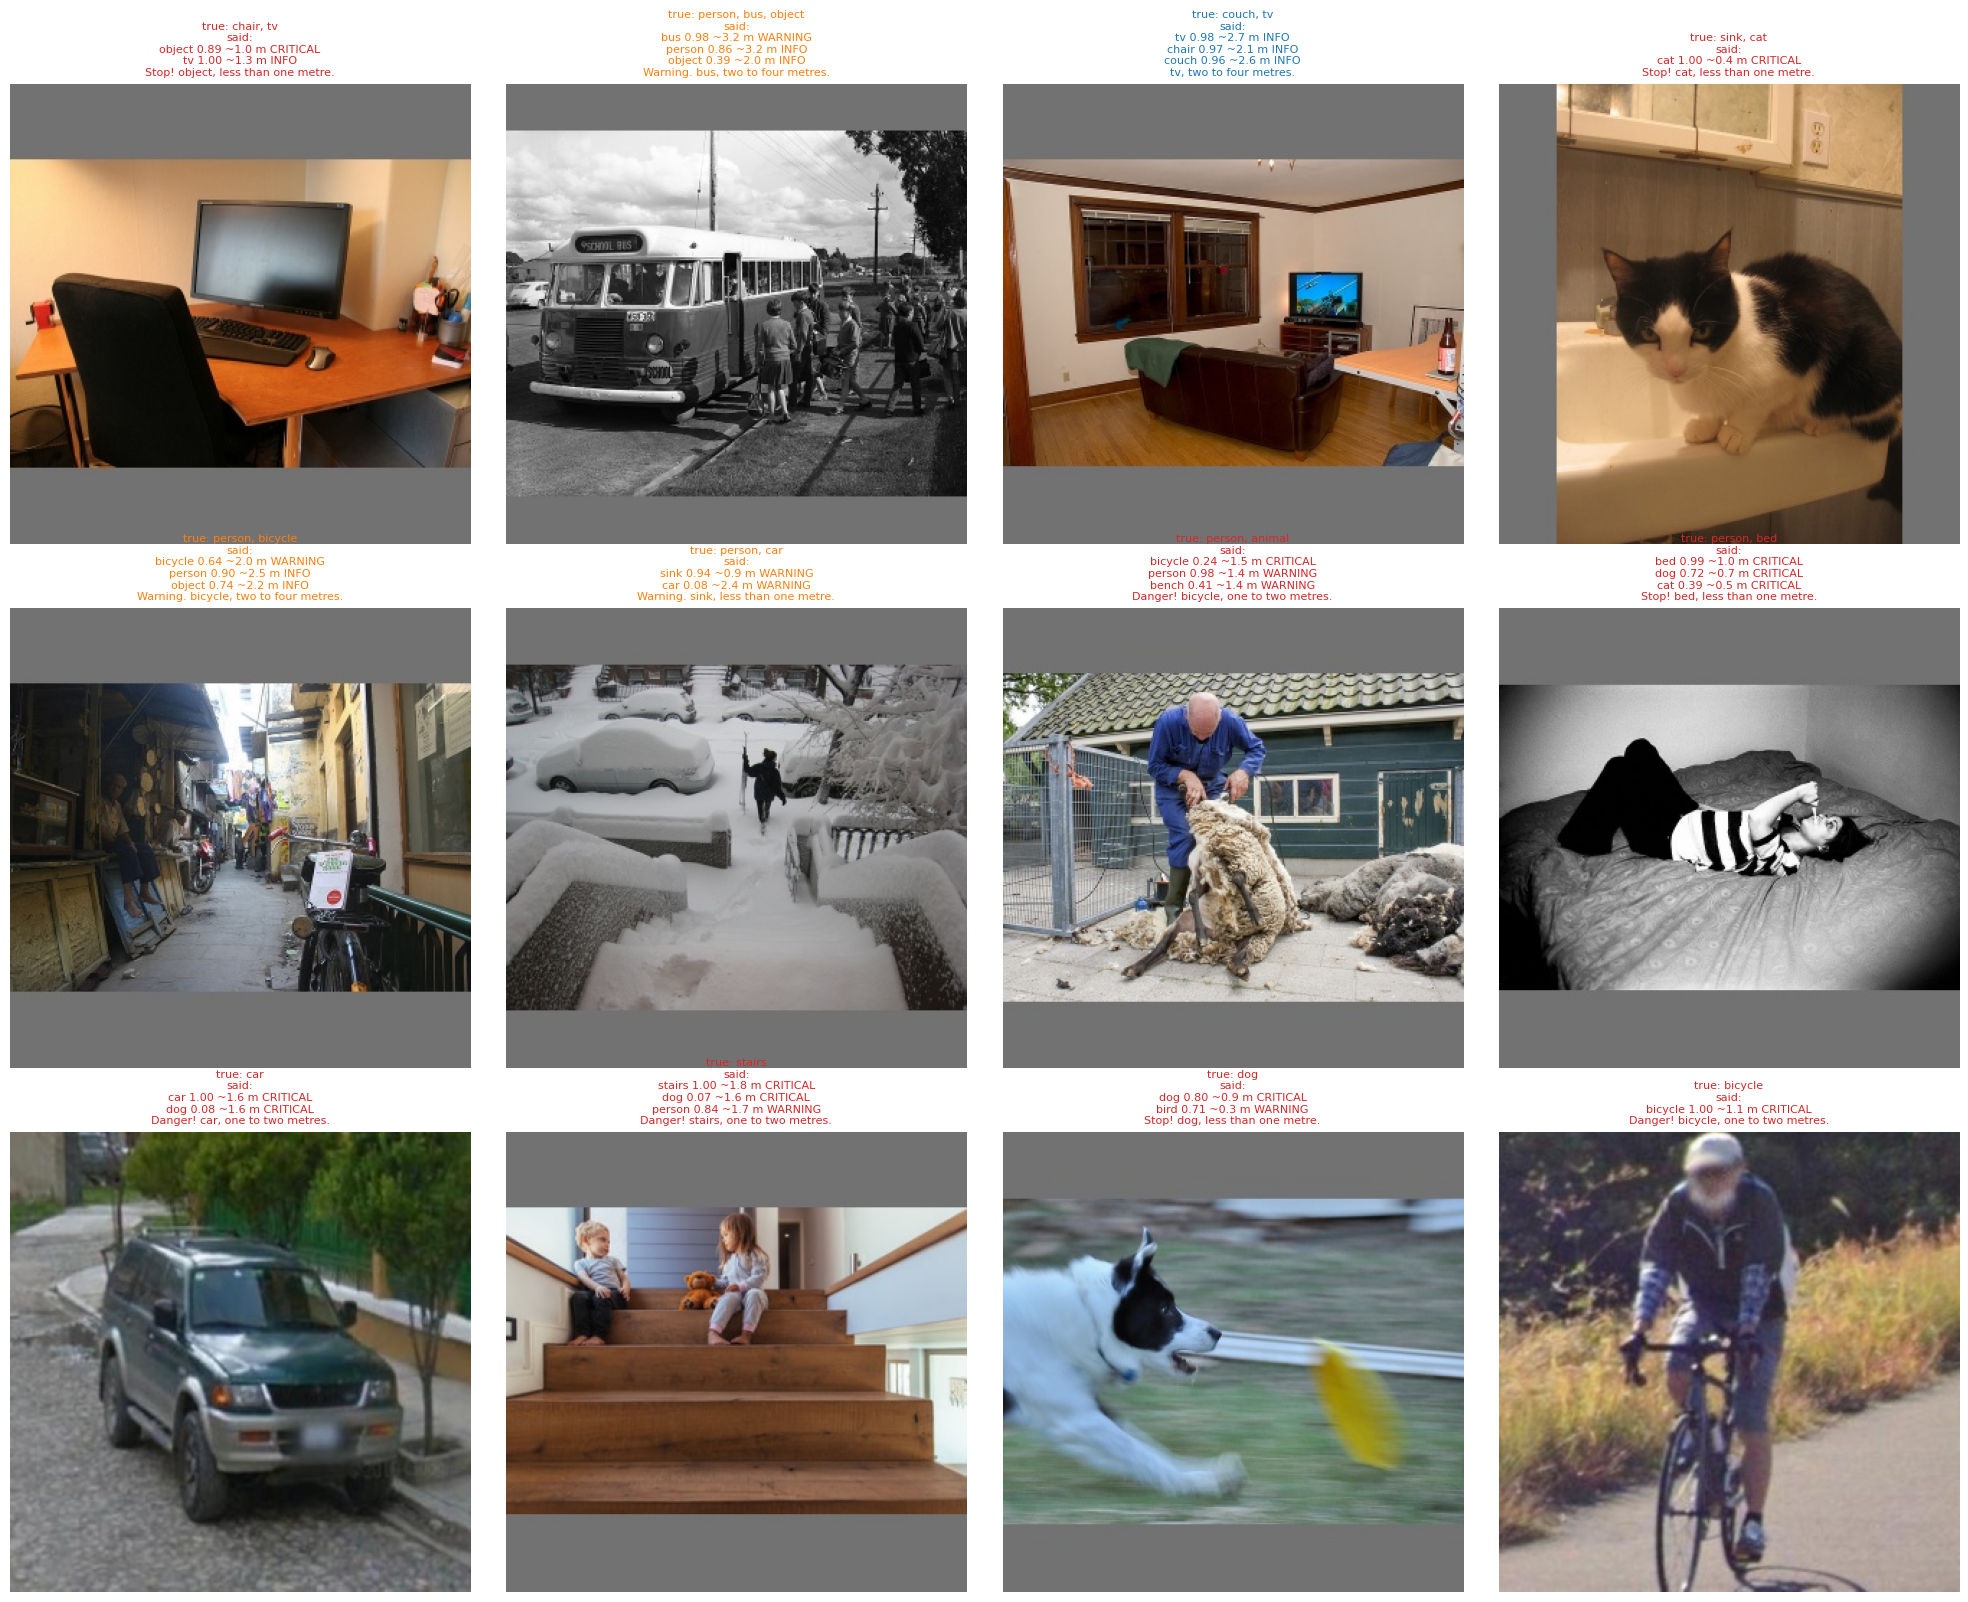

  1000/2700 images
  2000/2700 images
0.1 percent of test pictures: nothing found | 0.8 percent: only a generic "object" | on average 2.04 objects per picture (at most TOP_K = 3)


In [19]:
# CELL 14 - ALERT DEMO: run the final int8 model on test pictures and show the alerts the device would give (every object it finds, most urgent first).
rng = random.Random(7)   # repeatable choice of demo pictures
t_paths = INDEX['test'][0]   # test picture paths
multi_ids = list(np.where(MULTI['test']['pres'].sum(1) >= 2)[0]); single_ids = list(np.where(MULTI['test']['pres'].sum(1) < 2)[0])   # pictures with several objects / with one
pick = rng.sample(multi_ids, min(8, len(multi_ids))) + rng.sample(single_ids, min(4, len(single_ids)))   # mostly several-object pictures
lg_d, sz_d = run_tflite(final_bytes, [t_paths[i] for i in pick])   # run the final model on them
colors = {0: 'gray', 1: 'tab:blue', 2: 'tab:orange', 3: 'tab:red'}   # title colour per priority level
fig, axes = plt.subplots(3, 4, figsize=(20, 16))   # a 3 x 4 grid
for ax, i, lg1, sz1 in zip(axes.flatten(), pick, lg_d, sz_d):   # one panel per picture
    dets = decide_all(lg1, sz1)   # the alerts for this picture
    true_names = ', '.join(CLASS_LIST[c] for c in np.where(MULTI['test']['pres'][i] > 0)[0])   # what is really in the picture
    lines = [f"{d['name']} {d['conf']:.2f}{' (unsure)' if d['unsure'] else ''} ~{d['metres']:.1f} m {PRIORITY_NAMES[d['priority']].upper()}" for d in dets] or ['(nothing found)']   # one line per detected object
    ax.imshow(plt.imread(t_paths[i]))   # the picture
    ax.set_title(f"true: {true_names}\nsaid:\n" + '\n'.join(lines) + f"\n{dets[0]['text'] or '(silent)'}" if dets else f"true: {true_names}\nsaid: (nothing found)", fontsize=8, color=colors[dets[0]['priority']] if dets else 'gray')   # truth, every alert, and the words of the most urgent one
    ax.axis('off')   # hide the axes
plt.tight_layout(); plt.show()   # draw the grid
lg_all, sz_all = run_tflite(final_bytes, t_paths)   # whole test split, to count how often nothing / only a generic object is announced
n_det = np.array([len(decide_all(l, s)) for l, s in zip(lg_all, sz_all)])   # alerts per picture
n_unsure = np.array([bool(d) and d[0]['unsure'] for d in (decide_all(l, s) for l, s in zip(lg_all, sz_all))])   # pictures announced only as a generic object
print(f'{(n_det == 0).mean() * 100:.1f} percent of test pictures: nothing found | {n_unsure.mean() * 100:.1f} percent: only a generic "object" | on average {n_det.mean():.2f} objects per picture (at most TOP_K = {TOP_K})')   # how often


### Speech clips (hard-coded, not generated live)
Every (class, distance band) sentence is spoken once here by a text-to-speech service and saved as a WAV file, with an alert tone in front (3 high beeps = critical, 2 medium = warning, 1 soft = info). With 27 classes and 3 speaking bands this makes 81 clips; several objects in one frame are played one after the other, most urgent first.

In [20]:
# CELL 15 - SPEECH: every word or sentence is spoken ONCE here by a text-to-speech engine and stored as a WAV file, so the device only plays files (no live speech synthesis). AUDIO_MODE 'clips' stores all 81 full sentences; 'fragments' stores about 33 short pieces (lead word, class name, distance phrase) that the device joins, which is far smaller.
from gtts import gTTS   # Google text-to-speech (needs internet, used only in this notebook)
from IPython.display import Audio, display   # play clips inside the notebook
AUDIO_DIR = Path(OUT) / 'audio'   # clips are written here
AUDIO_DIR.mkdir(exist_ok=True)   # create the folder

def tone(freq, seconds, vol=0.5):   # a short beep as 16-bit samples
    t = np.arange(int(AUDIO_RATE * seconds)) / AUDIO_RATE   # time axis
    env = np.minimum(1.0, np.minimum(t, seconds - t) / 0.01)   # 10 ms fade in/out so there is no click
    return (vol * env * np.sin(2 * np.pi * freq * t) * 32767).astype(np.int16)   # sine wave scaled to 16-bit

def silence(seconds):   # a gap of silence
    return np.zeros(int(AUDIO_RATE * seconds), dtype=np.int16)   # zeros

def beeps(priority):   # the alert tone that comes before the words: more urgent = more and higher beeps
    if priority == 3:   # critical: three fast high beeps
        return np.concatenate([tone(1200, 0.09), silence(0.05), tone(1200, 0.09), silence(0.05), tone(1200, 0.09)])   # beep beep beep
    if priority == 2:   # warning: two medium beeps
        return np.concatenate([tone(800, 0.10), silence(0.06), tone(800, 0.10)])   # beep beep
    return tone(500, 0.10, 0.35)   # info: one short soft beep

def speak_pcm(text):   # text -> 16-bit mono samples at AUDIO_RATE
    for attempt in range(4):   # the online service sometimes fails
        try:   # try to synthesise
            gTTS(text, lang=SPEECH_LANG).save('/content/_tts.mp3')   # speech as an MP3 file
            raw = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', '/content/_tts.mp3', '-ar', str(AUDIO_RATE), '-ac', '1', '-f', 's16le', 'pipe:1'],   # convert to raw samples
                                 capture_output=True, check=True).stdout   # read ffmpeg's output
            return np.frombuffer(raw, dtype=np.int16)   # samples
        except Exception as e:   # network or conversion problem
            print('  retrying after:', str(e)[:80])   # say why
            time.sleep(2 + attempt * 3)   # wait a little longer each time
    raise RuntimeError('text-to-speech failed 4 times: check the internet connection')   # give up loudly

def beep_len(priority):   # length of the alert beeps of one priority in seconds
    return len(beeps(priority)) / AUDIO_RATE   # samples / rate

def write_wav(path, pcm):   # save 16-bit samples as a WAV file in the chosen storage format
    if AUDIO_CODEC == 'pcm_s16le':   # plain 16-bit samples
        with wave.open(str(path), 'wb') as w:   # standard WAV writer
            w.setnchannels(1); w.setsampwidth(2); w.setframerate(AUDIO_RATE)   # mono, 16-bit, sample rate
            w.writeframes(pcm.tobytes())   # the samples
    else:   # compressed (for example 8-bit mu-law: half the size, trivial to decode on a microcontroller)
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-f', 's16le', '-ar', str(AUDIO_RATE), '-ac', '1', '-i', 'pipe:0', '-acodec', AUDIO_CODEC, str(path)],   # ffmpeg converts the samples
                       input=pcm.tobytes(), check=True)   # feed the samples in

manifest = []   # one entry per playable alert (class x band)
t0 = time.time()   # start the clock
if AUDIO_MODE == 'clips':   # full sentences, one file per alert
    for cid in range(NC):   # every class
        for band in range(3):   # the three speaking bands (very close, close, near)
            pr = priority_of(cid, band)   # priority of this clip
            text = sentence(cid, band)   # the words
            pcm = np.concatenate([beeps(pr), silence(0.12), speak_pcm(text)])   # beeps, short gap, then the words
            path = AUDIO_DIR / clip_name(cid, band)   # clip file
            write_wav(path, pcm)   # save it
            manifest.append(dict(cls=CLASS_LIST[cid], band=BAND_NAMES[band], priority=PRIORITY_NAMES[pr], text=text, file=path.name,   # what it is
                                 seconds=round(len(pcm) / AUDIO_RATE, 2), bytes=path.stat().st_size))   # how long and how big
        if (cid + 1) % 5 == 0:   # progress
            print(f'  {cid + 1}/{NC} classes done ({time.time() - t0:.0f} s)')   # show it
    stored_bytes = sum(m['bytes'] for m in manifest)   # storage needed for all clips
    FRAG = {}   # no fragments in this mode
else:   # 'fragments': store each short piece once, the device joins them
    GAP_S, BEEP_GAP_S = 0.05, 0.12   # silence between the pieces / after the beeps (seconds)
    pieces = {}   # text -> (file name, samples)
    def piece(text, tag):   # speak one piece once and keep it
        if text not in pieces:   # not spoken yet
            pcm_ = speak_pcm(text)   # synthesise it
            fn = f'{tag}_{re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")}.wav'   # file name from the words
            write_wav(AUDIO_DIR / fn, pcm_)   # save it
            pieces[text] = (fn, pcm_)   # remember it
        return pieces[text]   # file name and samples
    for cid in range(NC):   # every class
        for band in range(3):   # the three speaking bands
            pr = priority_of(cid, band)   # priority of this alert
            lead = 'Stop!' if (band == 0 and pr == 3) else LEAD.get(pr, '')   # the same opening word as the full sentence
            parts = ([piece(lead, 'lead')] if lead else []) + [piece(CLASS_INFO[CLASS_LIST[cid]][0], 'name'), piece(DIST_WORDS[band], 'dist')]   # lead word, class name, distance phrase
            secs = beep_len(pr) + BEEP_GAP_S + sum(len(p[1]) / AUDIO_RATE for p in parts) + GAP_S * (len(parts) - 1)   # beeps + gap + pieces + gaps between pieces
            manifest.append(dict(cls=CLASS_LIST[cid], band=BAND_NAMES[band], priority=PRIORITY_NAMES[pr], text=sentence(cid, band), file=clip_name(cid, band),   # what it is (file = the key the alert manager uses)
                                 parts=[p[0] for p in parts], seconds=round(secs, 2), bytes=0))   # the pieces to join, total length, nothing stored per alert
    stored_bytes = sum((AUDIO_DIR / p[0]).stat().st_size for p in pieces.values())   # storage needed for the pieces
    FRAG = {t: p for t, p in pieces.items()}   # kept for the preview below
    print(f'{len(pieces)} pieces stored; the beeps are NOT stored (the device generates them: priority 3 = 3 x 1200 Hz 90 ms, 2 = 2 x 800 Hz 100 ms, 1 = 1 x 500 Hz 100 ms)')   # explain
json.dump(dict(mode=AUDIO_MODE, codec=AUDIO_CODEC, rate_hz=AUDIO_RATE, gap_s=0.05, beep_gap_s=0.12, alerts=manifest), open(AUDIO_DIR / 'audio_manifest.json', 'w'), indent=1)   # list of everything for the firmware
total = stored_bytes   # bytes of audio the device has to store
print(f"{len(manifest)} alerts | stored audio {total / 1e3:.0f} KB ({AUDIO_MODE}, {AUDIO_CODEC}, {AUDIO_RATE} Hz) | longest alert {max(m['seconds'] for m in manifest):.1f} s")   # totals

def preview(cid, band):   # the samples of one alert as the device would play them
    pr = priority_of(cid, band)   # priority
    if AUDIO_MODE == 'clips':   # one file
        return np.concatenate([beeps(pr), silence(0.12), speak_pcm(sentence(cid, band))])   # beeps + words
    m = next(x for x in manifest if x['file'] == clip_name(cid, band))   # the entry of this alert
    chunks = [beeps(pr), silence(BEEP_GAP_S)]   # beeps and the gap
    for k, fn in enumerate(m['parts']):   # every piece
        chunks += ([silence(GAP_S)] if k else []) + [next(p[1] for p in pieces.values() if p[0] == fn)]   # a gap between pieces, then the piece
    return np.concatenate(chunks)   # joined

for name in ('car_very_close.wav', 'person_close.wav', 'chair_near.wav'):   # one alert of each priority type to listen to
    print(name, '->', next(m['text'] for m in manifest if m['file'] == name))   # its words
    cid_ = next(i for i, n in enumerate(CLASS_LIST) if name.startswith(folder_name(n) + '_'))   # class of this example
    band_ = next(b for b in range(3) if name.endswith(BAND_NAMES[b].replace(' ', '_') + '.wav'))   # band of this example
    display(Audio(preview(cid_, band_), rate=AUDIO_RATE))   # play button (samples joined in memory)


33 pieces stored; the beeps are NOT stored (the device generates them: priority 3 = 3 x 1200 Hz 90 ms, 2 = 2 x 800 Hz 100 ms, 1 = 1 x 500 Hz 100 ms)
81 alerts | stored audio 120 KB (fragments, adpcm_ima_wav, 6000 Hz) | longest alert 4.5 s
car_very_close.wav -> Stop! car, less than one metre.


person_close.wav -> Warning. person, one to two metres.


chair_near.wav -> chair, two to four metres.


### Alert manager
The rules around the clips: do not repeat the same warning every frame (cooldowns), speak again when an object gets closer or the alert becomes more urgent, and let a more urgent clip interrupt a less urgent one. With several objects in a frame the most urgent one that is allowed to play right now is chosen; an object that was just announced stays quiet so the next one gets its turn. The demo shows a car approaching while a person stands nearby.

In [21]:
# CELL 16 - ALERT MANAGER (what the device does with the decisions): no repeating the same warning every frame, closer = speak again, urgent = interrupt.
DURATION = {m['file']: m['seconds'] for m in manifest}   # clip name -> length in seconds

class AlertManager:   # decides which clip (if any) to play for each camera frame
    def __init__(self):   # start with nothing played
        self.last = {}   # class id -> the last alert that was spoken for it
        self.busy_until = 0.0   # time when the current clip ends
        self.playing = 0   # priority of the clip being played
        self.playing_band = 9   # distance band of the clip being played
    def step(self, now, d):   # d = one alert from decide_all() for the current frame
        if d['priority'] == 0:   # far away: stay silent
            return None   # nothing to play
        prev = self.last.get(d['cls'])   # last alert for this class
        closer = prev is not None and d['band'] < prev['band']   # the object came into a closer band
        stronger = prev is not None and d['priority'] > prev['priority']   # the alert became more urgent
        if prev is not None and not (closer or stronger) and now - prev['t'] < COOLDOWN_S[d['priority']]:   # same situation announced recently
            return None   # do not repeat yet
        if now < self.busy_until and d['priority'] <= self.playing and d['band'] >= self.playing_band:   # something equally urgent is playing and this is not closer
            return None   # do not interrupt it (a higher priority OR a closer object does interrupt)
        self.last[d['cls']] = dict(t=now, band=d['band'], priority=d['priority'])   # remember this alert
        self.busy_until = now + DURATION[d['clip']]   # the clip will occupy the speaker for this long
        self.playing = d['priority']   # remember how urgent it is
        self.playing_band = d['band']   # and how close the object is
        return d['clip']   # play this file

    def frame(self, now, dets):   # all alerts of one camera frame, most urgent first -> (clip, alert) of the first one that may be played now
        for d in dets:   # the most urgent object first
            clip = self.step(now, d)   # may it be played now? (cooldowns, interruption rules)
            if clip:   # yes
                return clip, d   # play it
        return None, None   # nothing to play in this frame

def fake_frame(objects):   # make model outputs for several objects, each (name, distance in metres): the formula of cell 2 run backwards
    logits = np.full(NC, -6.0); sizes = np.full(NC, 0.1)   # nothing present, harmless sizes
    for name, metres in objects:   # each object
        cid = CLASS_ID[name]   # class id
        logits[cid] = 6.0   # confidently present
        sizes[cid] = np.clip(CLASS_INFO[name][1] / (metres * 2 * TAN_HALF), 0.02, 1.0)   # apparent size that gives this distance
    return logits, sizes   # model-style outputs

scenario = ([(t / 5, [('car', max(0.5, 8.0 - t / 5)), ('person', 3.0)]) for t in range(0, 41)]   # 0-8 s: a car approaches from 8 m to 0.5 m while a person stands 3 m away
            + [(9 + t / 5, [('pothole', 1.5), ('person', 3.0)]) for t in range(0, 11)]   # 9-11 s: a pothole at 1.5 m and the person
            + [(12 + t / 5, [('chair', 2.5)]) for t in range(0, 16)])   # 12-15 s: a chair 2.5 m away
mgr = AlertManager()   # a fresh manager
print(f"{'time':>6s}  {'objects in the frame':32s} {'priority':9s} clip played")   # header
for now, objs in scenario:   # 5 camera frames per second
    dets = decide_all(*fake_frame(objs))   # the alerts for this frame
    clip, d = mgr.frame(now, dets)   # does the manager want to play something?
    if clip:   # only print the moments when a clip starts
        print(f'{now:5.1f}s  {", ".join(f"{n} {m:.1f} m" for n, m in objs):32s} {PRIORITY_NAMES[d["priority"]]:9s} {clip}  "{d["text"]}"')   # the event


  time  objects in the frame             priority  clip played
  0.0s  car 8.0 m, person 3.0 m          info      person_near.wav  "person, two to four metres."
  3.2s  car 4.8 m, person 3.0 m          warning   car_near.wav  "Warning. car, two to four metres."
  5.8s  car 2.2 m, person 3.0 m          critical  car_close.wav  "Danger! car, one to two metres."
  6.4s  car 1.6 m, person 3.0 m          critical  car_very_close.wav  "Stop! car, less than one metre."
 10.4s  pothole 1.5 m, person 3.0 m      critical  pothole_close.wav  "Danger! pothole, one to two metres."
 14.8s  chair 2.5 m                      info      chair_near.wav  "chair, two to four metres."


### Export
Writes `alert_config.json` (everything the firmware needs: tensor formats, class table, detection and distance rules, priority table, cooldowns), copies the output folder to Drive and prints the final summary.

In [22]:
# CELL 17 - EXPORT: write the settings file the firmware needs, copy everything to Drive and print the final summary.
outs = it.get_output_details()   # output tensors of the final model
cfg = dict(   # everything the device code must know
    model=dict(file=Path(FINAL_TFLITE).name, input_shape=[1, IMG_SIZE, IMG_SIZE, 3], input_dtype=IN['dtype'].__name__,   # file and input format
               input_scale=float(IN_SCALE), input_zero_point=int(IN_ZP), preprocess=f'pad the frame to a square with grey 114 (exactly like the dataset letterbox, which is 320x320), then shrink it to {IMG_SIZE}x{IMG_SIZE} with area averaging (anti-aliased), then x = pixel / 127.5 - 1, then q = round(x / scale) + zero_point',   # how to prepare a frame
               outputs=[dict(index=int(o['index']), shape=[int(s) for s in o['shape']], scale=float(o['quantization'][0]), zero_point=int(o['quantization'][1]),   # output tensors
                             meaning='presence logit of every class (probability = sigmoid(logit / temperature))' if o['shape'][-1] == NC else 'size of every class = sqrt(box area), 0..1, shape 27 x 1') for o in outs]),   # what each means
    classes=[dict(id=i, name=n, spoken=CLASS_INFO[n][0], ref_size_m=CLASS_INFO[n][1], hazard=CLASS_INFO[n][2]) for i, n in enumerate(CLASS_LIST)],   # class table
    distance=dict(formula='metres = ref_size_m / (size_used * 2 * tan(hfov / 2)), limited to 0.3-30; size_used >= fill_size means very close', fill_size=FILL_SIZE, hfov_deg=HFOV_DEG, band_edges_m=list(BAND_LIMITS_M), band_names=BAND_NAMES),   # distance rule
    priority=dict(names=PRIORITY_NAMES, table=PRIORITY_TABLE, cooldown_s={str(k): v for k, v in COOLDOWN_S.items()}),   # priority rule
    calibration=dict(temperature=CAL['temp'], threshold=CAL['thr'], class_thresholds={n: CAL['thr_c'][i] for i, n in enumerate(CLASS_LIST)}, size_slope=CAL['a'], size_offset=CAL['b'], size_margin=CAL['margin'],   # corrections fitted in cell 13b
                     how='p = sigmoid(logit / temperature); class c is present when p >= class_thresholds[c] (threshold is only the fallback); for every present class: size_used = clip((slope * size[c] + offset) * (1 + margin), 0.02, 1); then apply the distance formula with that class\'s ref_size_m'),   # how the device applies them
    detection=dict(top_k=TOP_K, unsure_min=UNSURE_MIN, unsure_rule='if no class reaches the threshold but the strongest has p >= unsure_min, announce it as the generic class object with that candidate\'s size', order='alerts are sorted by priority (highest first), then distance band (closest first), then probability'),   # several objects per frame
    audio=dict(mode=AUDIO_MODE, codec=AUDIO_CODEC, rate_hz=AUDIO_RATE, folder='audio', manifest='audio/audio_manifest.json', how='mode clips: play the file named by the alert; mode fragments: generate the beeps, then play the listed pieces in order with the gaps given in the manifest'),   # speech clips or pieces
    memory=dict(model_kb=round(len(final_bytes) / 1e3), audio_kb=round(total / 1e3), tensor_arena_estimate_kb=round(arena_kb(final_bytes))))   # what has to be stored and the RAM estimate
json.dump(cfg, open(f'{OUT}/alert_config.json', 'w'), indent=1)   # save it
shutil.copytree(OUT, OUT_DRIVE, dirs_exist_ok=True)   # copy the whole output folder to Drive
print('saved to', OUT_DRIVE)   # where to find it
for p in sorted(Path(OUT_DRIVE).glob('*')):   # list the files
    print(f'  {p.name:32s}', f'{p.stat().st_size / 1e6:8.2f} MB' if p.is_file() else '  (folder)')   # name and size
print('\n' + '=' * 62)   # separator
print(f"FINAL MODEL '{best}': {len(final_bytes) / 1e6:.2f} MB | test mAP {final_cal['map']:.4f} | size error {final_test['size_mae']:.4f} | band accuracy {final_cal['band_acc']:.3f}")   # summary line
print(f"with the per-class thresholds: precision {final_cal['precision']:.3f} recall {final_cal['recall']:.3f} F1 {final_cal['f1']:.3f} | danger objects found {final_cal['danger_recall']:.3f} | old-style top-1 {final_cal['top1']:.4f}")   # detection numbers (at the calibrated threshold)
print(f"near objects (< 2 m) reported as 2 m or farther: {final_cal['missed_near'] * 100:.1f} percent | audio: {len(manifest)} alerts, {total / 1e3:.0f} KB stored")   # safety number and audio size
print(f"STORAGE: model {len(final_bytes) / 1e3:.0f} KB + audio {total / 1e3:.0f} KB = {(len(final_bytes) + total) / 1e3:.0f} KB | estimated RAM for the model's tensors (tensor arena): about {arena_kb(final_bytes):.0f} KB")   # the TinyML numbers


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


saved to /content/drive/MyDrive/IRP/irp-model-compact
  alert_config.json                    0.01 MB
  audio                              (folder)
  best.weights.h5                      7.70 MB
  float.weights.h5                     7.70 MB
  float_model.keras                    7.84 MB
  irp_navigation_v6.tflite             0.88 MB
  model_int8_ptq.tflite                0.88 MB
  phase1_best.weights.h5               3.95 MB
  training_curves.png                  0.10 MB

FINAL MODEL 'int8 PTQ': 0.88 MB | test mAP 0.7859 | size error 0.0835 | band accuracy 0.611
with the per-class thresholds: precision 0.573 recall 0.766 F1 0.655 | danger objects found 0.870 | old-style top-1 0.6444
near objects (< 2 m) reported as 2 m or farther: 5.8 percent | audio: 81 alerts, 120 KB stored
STORAGE: model 885 KB + audio 120 KB = 1005 KB | estimated RAM for the model's tensors (tensor arena): about 373 KB
